In [ ]:
try:
    spark.stop()
except Exception as e:
    print(e)

In [1]:
#!yarn application -status application_1782979140233_15545553
    # application_1782979140233_15429775
    
!yarn application -kill application_1782979140233_15545553

Application application_1782979140233_15545553 has already finished. 


In [1]:
from pathlib import Path
import sys
import os
import json
import math
import datetime
import warnings
from datetime import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import joblib
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)
import findspark
findspark.init()

from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as func
from pyspark.sql.functions import col, desc, udf
from pyspark.sql.types import StructType, StructField, StringType

from ortools.linear_solver import pywraplp

warnings.filterwarnings("ignore")




# Backflow imports
from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools


# Matplotlib font

from pyspark.sql import SparkSession
spark3conf_best = {
    "spark.submit.deployMode": "client",
    "spark.yarn.queue": "root.growstrategy_group_prod",

    "spark.driver.memory": "24g",
    "spark.driver.memoryOverhead": "4g",

    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "80",
    "spark.dynamicAllocation.initialExecutors": "80",
    "spark.dynamicAllocation.maxExecutors": "120",
    "spark.dynamicAllocation.shuffleTracking.enabled": "true",

    "spark.executor.cores": "2",
    "spark.executor.memory": "12g",
    "spark.executor.memoryOverhead": "8g",

    "spark.default.parallelism": "1200",
    "spark.sql.shuffle.partitions": "1200",

    "spark.sql.adaptive.enabled": "true",
    "spark.sql.adaptive.coalescePartitions.enabled": "true",
    "spark.sql.adaptive.skewJoin.enabled": "true",
    "spark.sql.adaptive.advisoryPartitionSizeInBytes": "134217728",

    "spark.sql.autoBroadcastJoinThreshold": "104857600",
    "spark.sql.broadcastTimeout": "3000",

    "spark.network.timeout": "600s",
    "spark.executor.heartbeatInterval": "60s",

    "spark.memory.fraction": "0.8",
    "spark.memory.storageFraction": "0.3",

    "spark.sql.execution.arrow.pyspark.enabled": "true",
    "spark.sql.execution.arrow.maxRecordsPerBatch": "5000",

    "mapred.input.dir.recursive": "TRUE",
    "hive.mapred.supports.subdirectories": "TRUE",

    "spark.serializer": "org.apache.spark.serializer.KryoSerializer",
    "spark.kryoserializer.buffer.max": "1024m",

    "spark.yarn.dist.archives": "hdfs://difed/user/dm/ENV/dlflow/v2/py3.7.15_for_tfcluster_63.tgz",
    "spark.executorEnv.PYSPARK_PYTHON": "./py3.7.15_for_tfcluster_63.tgz/py3.7.15_for_tfcluster/bin/python3",

    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",

    "spark.sql.merge.mode": "FAST",
    "spark.sql.merge.enabled": "TRUE",
}

builder = (
    SparkSession
    .builder
    .appName("flowback_euen_v22")
    .master("yarn")
)

for k, v in spark3conf_best.items():
    builder = builder.config(k, v)

spark = builder.enableHiveSupport().getOrCreate()

print("[Info] Spark Version:", spark.version)
print("[Info] Spark Queue:", spark.conf.get("spark.yarn.queue"))
print("[Info] Spark App ID:", spark.sparkContext.applicationId)
print(spark.conf.get("spark.yarn.queue"))
print(spark.sparkContext.applicationId)

load metric func from causalml...


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
Application Id: application_1782979140233_21598287, Tracking URL: http://bigdata-nmg-hdprm00.nmg01:8088/proxy/application_1782979140233_21598287/
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 57184)


[Info] Spark Version: 3.2.0-101
[Info] Spark Queue: root.growstrategy_group_prod
[Info] Spark App ID: application_1782979140233_21598287
root.growstrategy_group_prod
application_1782979140233_21598287


In [2]:
plt.rcParams.update({
    # 按系统优先级填写中文字体
    "font.sans-serif": [
        "Microsoft YaHei",   # Windows 微软雅黑
        "SimHei",            # Windows 黑体
        "Arial Unicode MS",  # MacOS
        "PingFang SC",       # MacOS 苹方
        "WenQuanYi Zen Hei"  # Linux
    ],
    "axes.unicode_minus": False,  # 解决负号 '-' 变成方框
})

In [3]:
import datetime
from itertools import product

# 生成一段日期列表。从 start_dt 开始，一天一天往前或往后走，收集够 degree_days 天，最后排序并返回最后 degree_days 个日期
def smart_generate_dt_list(start_dt, degree_days, step=1, format="%Y-%m-%d", flag=1, 
                          ignore_dts=[]):
    
    strptime, strftime = datetime.datetime.strptime, datetime.datetime.strftime
    
    gen_dts = []
    curr_dt = start_dt
    
    while len(gen_dts)<degree_days:
        if curr_dt not in ignore_dts:
            gen_dts.append(curr_dt)
        
        __dt = strftime(strptime(curr_dt, format) - datetime.timedelta(1), format)
        if flag == 1:
            __dt = strftime(strptime(curr_dt, format) + datetime.timedelta(1), format)
            
        curr_dt = __dt
    
        
    gen_dts = sorted(gen_dts)
    if gen_dts[-1] != start_dt:
        gen_dts.append(start_dt)
    return sorted(gen_dts)[-degree_days:]

In [4]:
# delta_cac:每多带来1个增量完单，需要多花多少钱

def calculate_delta_metrics(df, group_name_1, group_name_2):
    # 计算通补delta cac、delta cvr函数
    # 取出当前 bucket 下的数据
    bucket_data = df

    # 分别取出 group_name_eve 为 group_name_1 和 group_name_2 的数据
    data_1 = bucket_data[bucket_data['group_name_eve'] == group_name_1]
    data_2 = bucket_data[bucket_data['group_name_eve'] == group_name_2]

    # 计算各自的总数量和 cost_7d 的总和
    total_count_1 = len(data_1)
    total_cost_1 = data_1['cost_7d'].sum()
    total_cvr_1 = data_1['pv_label_7d'].sum()

    total_count_2 = len(data_2)
    total_cost_2 = data_2['cost_7d'].sum()
    total_cvr_2 = data_2['pv_label_7d'].sum()

    # cac1，2:是人均成本; cvr1,2是人均7日完单。
    # 实验组每人平均成本 - 对照组每人平均成本 / 实验组每人平均订单 - 对照组每人平均订单
    cac_1 = total_cost_1 / total_count_1 if total_count_1 > 0 else 0
    cac_2 = total_cost_2 / total_count_2 if total_count_2 > 0 else 0

    cvr_1 = total_cvr_1 / total_count_1 if total_count_1 > 0 else 0
    cvr_2 = total_cvr_2 / total_count_2 if total_count_2 > 0 else 0

    delta_cost = cac_1 - cac_2
    delta_cvr = cvr_1 - cvr_2
    delta_cac = delta_cost / delta_cvr if delta_cvr != 0 else 0

    return delta_cac, delta_cvr

In [5]:
def calculate_percentile_thresholds(data, columns, quantiles):
    thresholds = {}
    for col in columns:
        if col in data.columns:
            # 使用 nvl 类似的功能，将 NaN 替换为 999
            filled_data = data[col].fillna(999)
            # 检查是否所有值都相同或为空
            if filled_data.nunique() > 1:  # 检查非空且唯一值的数量
                thresholds[col] = filled_data.quantile(quantiles).values
            else:
                # 如果所有值都相同，设置默认的阈值（这里设置为 None 或其他默认值）
                thresholds[col] = np.array([None] * len(quantiles))
    return thresholds # 一个字典，记录每个字段的 10 分位切分阈值。

In [6]:
def assign_quantile_buckets(data, quantile_thresholds, columns, quantiles):
    for col in columns:
        if col in data.columns:
            new_col_name = f"{col}_per"
            thresholds = quantile_thresholds[col]
            if thresholds is not None:
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                # 使用 pd.cut 将数据分到对应的区间中
                data[new_col_name] = pd.cut(data[col].fillna(999), bins=bins, labels=labels, include_lowest=True, duplicates='drop')
    return data

In [7]:
def move_threshold_main(data_pdf, group_name_list, columns, train_dates, val_dates):
    all_val_data = []
    quantile_thresholds_list = []
    # 滑动窗口处理
    for i in range(len(val_dates)):
        # 选取当前滑动窗口的train_dt和val_dt
        start_date = train_dates[i]
        train_dt = smart_generate_dt_list(start_dt=start_date, degree_days=7, flag=-1) # 基于smart_generate_dt_list对train日期向前扩展7天。
        val_dt = [val_dates[i]]
        print(train_dt)
        print(val_dt) # 验证 06-24 时，用 06-17~06-23 训练 ; 验证 06-25 时，也用 06-17~06-23 训练 ; 验证 06-26 时，也用 06-17~06-23 训练
        train_data = data_pdf[data_pdf['dt'].isin(train_dt)]
        quantiles = np.arange(0.1, 1.0, 0.1)  # 从0.1到0.9，9个分位点--10桶
        
        # 计算分位数阈值：quantile_thresholds
        '''
        {'cost_1':  [0.22, 0.35, ... , 0.88],
         'left65':  [left65的10%, left65的20%, ..., left65的90%],
         'left853': [left853的10%, left853的20%, ..., left853的90%] }
        '''
        quantile_thresholds = calculate_percentile_thresholds(train_data, columns, quantiles)
        quantile_thresholds_list.append(quantile_thresholds)
        
        
        # 对验证集数据进行分位数划分
        val_data = data_pdf[data_pdf['dt'].isin(val_dt)]

        for col in columns:
            if col in val_data.columns:
                new_col_name = f"{col}_per"
                thresholds = quantile_thresholds[col]
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                val_data[new_col_name] = pd.cut(val_data[col].fillna(999), bins=bins, labels=labels, include_lowest=True)
        all_val_data.append(val_data)
        
    # 合并所有的val_data
    combined_val_data = pd.concat(all_val_data).reset_index(drop=True)    
    # 分配训练集
    quantiles = np.arange(0.1, 1.0, 0.1)
    use_train_all = assign_quantile_buckets(train_data, quantile_thresholds, columns, quantiles)
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    return quantile_thresholds_list, train_df, val_df



In [8]:
# cominbed_val_data
'''
pid   dt          group_name_eve   real_treatment   pv_label_7d   cost_7d     cost_1    left63   left853   left65   cost_1_per   left63_per   left853_per   left65_per   left65_minus_left63_per   left853_minus_left63_per
p001  2026-06-24  DS空白               0                   0          0.0       0.13     0.0021   0.0032    0.0040   0.3          0.4          0.5           0.6             0.7                      0.5
p002  2026-06-24  留存6张3元            1                   1          0.8       0.21     0.0065   0.0051    0.0072   0.5          0.8          0.7           0.9             0.8                      0.3
p003  2026-06-25  8元留存5张3           2                   2          1.4       0.44     0.0010   0.0044    0.0035   0.8          0.2          0.6           0.5             0.4                      0.9
p004  2026-06-30  10元留存5张3          4                   0          0.0       0.31     0.0080   0.0071    0.0095   0.7          0.9          0.8           1.0             0.9                      0.4
'''

'\npid   dt          group_name_eve   real_treatment   pv_label_7d   cost_7d     cost_1    left63   left853   left65   cost_1_per   left63_per   left853_per   left65_per   left65_minus_left63_per   left853_minus_left63_per\np001  2026-06-24  DS空白               0                   0          0.0       0.13     0.0021   0.0032    0.0040   0.3          0.4          0.5           0.6             0.7                      0.5\np002  2026-06-24  留存6张3元            1                   1          0.8       0.21     0.0065   0.0051    0.0072   0.5          0.8          0.7           0.9             0.8                      0.3\np003  2026-06-25  8元留存5张3           2                   2          1.4       0.44     0.0010   0.0044    0.0035   0.8          0.2          0.6           0.5             0.4                      0.9\np004  2026-06-30  10元留存5张3          4                   0          0.0       0.31     0.0080   0.0071    0.0095   0.7          0.9          0.8           1.0             0.9  

In [9]:
# 判断哪些分桶组合样本量足够，哪些组合样本量太小；样本够的先保留下来，样本不够的交给下一阶段继续合并。
# 在当前 stage 下，把组合分成“大样本组合”和“小样本组合”。


def split_small_data_debug(small_data, columns, all_columns, min_count):
    
    
    # 它不需要直接传 stage，因为调用时已经把当前 stage 拆成了columns, min_count = stage
    # 仅使用指定列进行分组和统计，但保留所有列, columns:当前 stage 用哪些字段判断样本量; all_columns:完整组合字段，用于后面生成映射
    combination_counts = small_data.groupby(columns)['pid'].count().reset_index(name='counts')
    print("step1.....")

    # 获取大于等于最小数量的组合
    large_combinations = combination_counts[combination_counts['counts'] >= min_count]
    small_combinations = combination_counts[combination_counts['counts'] < min_count]
    
    print("step2.....")


    # 根据组合数量大于等于最小数量的组合，拆出数据，并保留完整的列
    large_sample_data = small_data.merge(large_combinations[columns], on=columns, how='inner')
    large_sample_data = large_sample_data[all_columns]

    # 根据组合数量小于最小数量的组合，拆出数据，并保留完整的列
    small_sample_data = small_data.merge(small_combinations[columns], on=columns, how='inner')
    #small_sample_data = small_sample_data[all_columns]

    print("step3.....")

    # 计算大组合和小组合的数据统计
    large_use_combinations = large_sample_data.groupby(all_columns).size().reset_index(name='counts')
    small_use_combinations = small_sample_data.groupby(all_columns).size().reset_index(name='counts')
    large_use_combinations = large_use_combinations[large_use_combinations['counts'] > 0]
    small_use_combinations = small_use_combinations[small_use_combinations['counts'] > 0]
    
    print("step4.....")

    return large_sample_data, small_sample_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations

# large/small_sample_data        # 大样本/小样本 用户明细
# large/small_combinations        # 当前阶段字段组合统计
# large/small_use_combinations   # 完整字段组合统计，用于后面建立完整组合到 bucket_num 的映射。



In [10]:
# 生成“桶号 -> 完整组合列表

def generate_bucket_mapping_final(stage_combinations, all_columns, stage_columns):
    bucket_mapping = {}
    bucket_id = 0
    
    # 创建一个字典来存储每个组合的bucket_id，键为base_combination， 值为bucket_id
    combination_to_bucket = {}

    # 处理每个阶段的大样本数的组合
    for stage_idx, (large_combinations, small_combinations, columns) in enumerate(stage_combinations):
        if large_combinations is not None and not large_combinations.empty:
            for index, row in large_combinations.iterrows():
                # combination是完整组合值 (0.1 0.7 0.2 0.3)
                combination = tuple(row[col] for col in all_columns)
                # 对应于降级后的组合 如(0.8 0.2 8888 8888), (0.7, 8888, 8888, 8888), (0.6, 8888, 8888, 8888)
                base_combination = tuple(row[col] for col in columns) + (8888,) * (len(all_columns) - len(columns))
                # 如果此时字典没有这种base_combination，则为这种组合分配新桶号
                if base_combination not in combination_to_bucket:
                    combination_to_bucket[base_combination] = bucket_id
                    bucket_id += 1
                if combination_to_bucket[base_combination] not in bucket_mapping:
                    bucket_mapping[combination_to_bucket[base_combination]] = []
                bucket_mapping[combination_to_bucket[base_combination]].append(combination)
    
    # 处理最后一个阶段的小样本数的组合，归为一个桶
    if small_combinations is not None and not small_combinations.empty:
        final_bucket_id = bucket_id
        for index, row in small_combinations.iterrows():
            combination = tuple(row[col] for col in all_columns)
            if final_bucket_id not in bucket_mapping:
                bucket_mapping[final_bucket_id] = []
            bucket_mapping[final_bucket_id].append(combination)
    
    return bucket_mapping


In [11]:
# 给每一行用户数据打最终 bucket_num。

def assign_bucket_num(row, columns, reverse_mapping, train_flag=False):
    prob_tuple = tuple(row[col] for col in columns)
    if train_flag and reverse_mapping.get(prob_tuple) is None:
        print("训练集组合出现与mapping表不重合部分:" + str(prob_tuple))
        #raise ValueError("训练集组合出现与mapping表不重合部分")
    return reverse_mapping.get(prob_tuple, -1)  # -1 表示没有找到对应的 bucket

In [12]:
# 桶内实验组配平/放缩，然后计算桶内每个 treatment 相对 control 的增量效果。

def process_df(df, control_name, bucket_name = 'bucket_name'):
    """
    :param df: DataFrame, with columns ['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost']
    :param control_name: string, 控制组实验名称
    :return: DataFrame
    """
    new_df = pd.DataFrame()
    for name, group in df.groupby(['bucket_name']): # 将每个桶中不同折扣的数据进行放缩
        sample = group['in_uv'].sum() # 该分桶下的总人数，也即某一桶下所有treatment总和
        group['zoom_sample'] = sample 
        group['zoom_first'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_uv, axis=1)
        
        # 如果这个 bucket 里的全部人都走这个 treatment，按照该 treatment 观测到的人均完单/人均成本，预计会产生多少完单/成本？
        group['zoom_finish'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_pv, axis=1) #桶级完单量
        group['zoom_cost'] = group.apply(lambda row: row.zoom_sample/row.in_uv * float(row.total_cost), axis=1)
        group['cvr_pv'] = group.apply(lambda row: row.zoom_finish/row.zoom_sample if row.zoom_sample != 0 else 0, axis=1)
        
        control_finish = group[group['exp_name'] == control_name]['zoom_finish'].sum()
        # control_first = group[group['exp_name'] == control_name]['zoom_first'].sum()
        control_cost = group[group['exp_name'] == control_name]['zoom_cost'].sum()
        group['zoom_delta_cost'] = group.apply(lambda row: row.zoom_cost - control_cost, axis=1)
        group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish, axis=1) # #桶级完单增量
        # group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish if row.zoom_finish - control_finish >= 0 else 0.1, axis=1)  #对于负弹的给一个较小的正值
        # group['zoom_delta_first'] = group.apply(lambda row: row.zoom_first - control_first, axis=1)
        new_df = new_df.append(group, ignore_index=True)
    return new_df


In [13]:

# 给后续的运筹定义基本的变量和编码
def data_prepare(df, para, bucket_col, group_name, control_name):
    """
    df: DataFrame, 数据源
    para: dict, 补贴形式
    bucket_col: string, 表示用户所在分桶的列
    group_name: string, 表示用户实际发券的分组
    control_name: string, Control组名称
    """
    dis_num = len(para)  # 补贴种类
    bucket_info = df[bucket_col].unique()  # 用户分桶信息
    bucket_num = len(bucket_info)  # 桶数量
    N = dis_num * bucket_num #决策量
    Y = np.ones((1, N))  # 目标人数最多 # 优化目标
    C = np.ones((1, N))  # 整体成本符合要求
    
    
    for i in range(bucket_num):  # 遍历桶
        bucket_id = bucket_info[i]  # 桶编码
        part_df = df[df[bucket_col] == bucket_id]  # 相应桶的数据
        sub = i * dis_num  # 索引位置。sub + para[row[group_name]]：就是当前桶、当前券型在 Y/C 数组里的位置
        used = set()
        if part_df[part_df[group_name] == control_name].empty:
            raise ValueError("出现空白为空的情况")
            
        # 把某一个桶里的每个券型，填到 OR-Tools 的 Y 和 C 数组里    
        for _, row in part_df.iterrows():
            if row[group_name] not in para:
                continue
            if row[group_name] == control_name:
                Y[0][sub + para[row[group_name]]] = row.zoom_delta_finish  # delta_CAC约束
                C[0][sub + para[row[group_name]]] = 0
            else:
                finish_uv = row.zoom_delta_finish  # delta_CAC约束
                coupon_cost = row.zoom_cost
                if finish_uv == 0 and coupon_cost == 0:
                    finish_uv = -100  # 保证不会被选择
                    coupon_cost = 0
                Y[0][sub + para[row[group_name]]] = finish_uv #相当于tao_ij，给这个bucket的用户发券j带来的增量。
                C[0][sub + para[row[group_name]]] = coupon_cost
            used.add(row[group_name])
        if len(used) != dis_num:
            raise ValueError("折扣数量不一致")

    C = C.reshape(-1)
    Y = Y.reshape(-1)
    return Y, C, bucket_info

In [14]:
def ortools_coupon(target, constraint, bucket_num, set_cost, para):
    """
    调用谷歌ortools包求解
    :param target: 目标表达式
    :param constraint: 约束表达式
    :param bucket_num: int, 桶数量
    :param set_cost: float, 成本信息
    :param para: dict, 补贴信息
    :return:
    """
    discount_num = len(para)
    N = len(target) # target：每个 bucket 每个券型的增量完单 PV
    st_exp_cost, obj_exp = None, None
    # 模型
    optimization_problem_type = 'SCIP'
    solver = pywraplp.Solver.CreateSolver(optimization_problem_type)
    
    # 创建N个二进制变量：每个 x[i] 表示：第 i 个“bucket + 券”方案是否被选中。
    x = [solver.IntVar(0, 1, 'x' + str(i)) for i in range(N)]
    
    # 优化目标：每个桶中不同券的delta_finish
    for i in range(N):
        if obj_exp is None:
            obj_exp = x[i] * target[i]
        else:
            obj_exp = obj_exp + x[i] * target[i] #累加成总增量完单
        #     print('obj_exp:')

    # 成本表达式: 每个桶中不同券的的cost 累加
    for i in range(N):
        if st_exp_cost is None:
            st_exp_cost = x[i] * constraint[i]
        else:
            st_exp_cost = st_exp_cost + x[i] * constraint[i] 
        #     print('st_exp_cost:')

    # 约束条件1: 每个桶只能选择一种折扣
    for i in range(bucket_num):
        bucket_vars = [x[j] for j in range(i * discount_num, (i + 1) * discount_num)]
        solver.Add(solver.Sum(bucket_vars) == 1)
        
    # 约束条件2: 成本约束 ：总成本 <= 目标CAC * 总增量完单
    solver.Add(st_exp_cost <= set_cost * obj_exp)   # st_exp_cost = 选中策略的总成本 ； obj_exp = 选中策略的总增量完单
    
    # 定义优化目标
    solver.Maximize(obj_exp) 
    # 调用求解器
    result_status = solver.Solve()
    res = []
    max_finish = 0
    if result_status == pywraplp.Solver.OPTIMAL:
        for i in range(len(x)):
            res.append(x[i].solution_value())
        max_finish = solver.Objective().Value()

    return (max_finish, res)

In [15]:
def or_convert(res, bucket_info, para):
    """
    :param res: 求解结果
    :param bucket_info: 桶信息
    :param para: 补贴信息
    :return: dict, 每个城市具体发券情况
    """
    new_para = dict((v, k) for k, v in para.items())
    discount_num = len(para)  # 补贴券数量
    coupon_ans = {}
    bucket_num = len(bucket_info) # 桶数量
    for i in range(bucket_num):
        tag = 0
        for j in range(i * discount_num, (i + 1) * discount_num):
            if res[j] == 1:
                index = j - i * discount_num
                coupon_ans[bucket_info[i]] = new_para[index]
                tag = 1
                break
        if tag == 0:
            try:
                coupon_ans[bucket_info[i]] = new_para[0]
            except:
                raise ValueError("未设置默认发券情况")
    return coupon_ans

In [16]:
def mock_use(df, coupon_ans, control_name, default_coupon, all_default_coupon_flag=False):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0
    
    # 处理传入的 coupon_ans 中的折扣
    for key, value in coupon_ans.items():
        treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
        control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    # 处理 bucket_name 为 -1 的情况
    default_keys = [-1]
    for key in default_keys:
        if key in df['bucket_name'].values:
            if all_default_coupon_flag:
                print("into all default & -1")
                value = coupon_ans[0] # 按通补指定的券来
                print(value)
            else:
                value = default_coupon # 为-1的桶分配线上的基线券
            treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
            control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
            if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
                # 未匹配到数据，继续处理下一个 key
                continue
            treat_sample += treat_df['zoom_sample'].values[0]
            treat_finish_uv += treat_df['zoom_first'].values[0]
            treat_finish_pv += treat_df['zoom_finish'].values[0]
            treat_cost += treat_df['zoom_cost'].values[0]
            control_sample += control_df['zoom_sample'].values[0]
            control_finish_uv += control_df['zoom_first'].values[0]
            control_finish_pv += control_df['zoom_finish'].values[0]
            control_cost += control_df['zoom_cost'].values[0]
            if treat_sample != control_sample:
                raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost, 
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac] 

In [17]:
# 仿真时采用新聚合方式模拟
def mock_use_simulation(df, control_name):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0

    # 遍历每个桶，取桶名对应的干预动作作为treat的模拟数据
    for value in list(df['bucket_name'].unique()):
        treat_df = df[(df['bucket_name'] == value) & (df['exp_name'] == df['bucket_value'])] #取bucket_value的券对应的RCT数据
        control_df = df[(df['bucket_name'] == value) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost,
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

In [18]:
def simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para,
                          processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon,
                          mock_use_simulation, simulation_flag):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y:
    C:
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    mock_use_simulation: function, 新版模拟使用优惠券的函数
    simulation_flag: bool, 是否用新版模拟仿真效果
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res_test_list = []
    discount_res = {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []

    color_mapping = {
        '555': 'brown',
        '留存6张3元': 'darkgreen',
        '留存6张5元': 'darkorange',
        '8元留存5张3': 'purple',
        '8元留存5张5元': 'pink'
        # add others...
    }
    
    #basic_colors = ['red', 'blue', 'green', 'yellow', 
               #'orange', 'purple', 'black', 'gray']

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        print('max_finish', max_finish)
#         print('res', res)
        discount_res = or_convert(res, bucket_info, discount_para)
#         print('discount_res', discount_res)
        discount_res[-1] = default_coupon  # 结果字典中添加关联不上的桶号-1发放兜底券
        discount_res_list.append(discount_res)

        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_res)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id #仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])

            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_res)
            discount_res_test = val_df.groupby('bucket_num')['bucket_num_discount'].first().to_dict()
            discount_res_test_list.append(discount_res_test)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id  # 仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            # 计算训练集结果
            train_ans = mock_use(processed_data, discount_res, control_name='DS空白',
                                 default_coupon=default_coupon)  # '5折5折5折(cap5)'
            # 计算测试集结果
            test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3], train_ans[-4], train_ans[-3]/train_ans[-4]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3], test_ans[-4], test_ans[-3]/test_ans[-4]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        mid = 5  # len(discount_res_list)//2
        discount_dict = discount_res_list[mid]
        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_dict)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])
            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_dict)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name,
                                 all_default_coupon_flag=True)
            test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name,
                                default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])

        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }

        # 真正彻底的通补
        train_x_total, train_y_total = calculate_delta_metrics(train_df, group_name, control_name)
        test_x_total, test_y_total = calculate_delta_metrics(val_df, group_name, control_name)
        tongbu_all_list.append([train_x_total, train_y_total, test_x_total, test_y_total])

        coordinates_total[group_name] = {
            'train': (train_x_total, train_y_total),
            'test': (test_x_total, test_y_total)
        }

    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'train_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        train_x_total, train_y_total = data['train']
        plt.scatter([train_x_total], [train_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'train_{group_name}_total', marker='.')
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')

    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'test_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        test_x_total, test_y_total = data['test']
        plt.scatter([test_x_total], [test_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'test_{group_name}_total', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list

In [19]:

def plot_multi_results(train_list_1, test_list_1, tongbu_list_1, tongbu_all_list_1, 
    train_list_2, test_list_2, tongbu_list_2, tongbu_all_list_2, 
    group_name_list, control_name):
    
    # 根据 group_name_list 和 control_name 生成实际使用的组名列表
    use_group_name_list = [name for name in group_name_list if name != control_name]
    color_list = ['green', 'purple', 'orange', 'red', 'yellow']
    # 提取第一组数据的训练集 x 和 y
    train_x_1 = [x[1] for x in train_list_1]
    train_y_1 = [x[2] for x in train_list_1]

    # 提取第一组数据的测试集 x 和 y
    test_x_1 = [x[1] for x in test_list_1]
    test_y_1 = [x[2] for x in test_list_1]

    # 提取第二组数据的训练集 x 和 y
    train_x_2 = [x[1] for x in train_list_2]
    train_y_2 = [x[2] for x in train_list_2]

    # 提取第二组数据的测试集 x 和 y
    test_x_2 = [x[1] for x in test_list_2]
    test_y_2 = [x[2] for x in test_list_2]
    
    plt.figure(figsize=(12, 6))

    # 绘制第一组的训练集散点图
    plt.subplot(1, 2, 1)
    plt.plot(train_x_1, train_y_1, marker='.', color='blue', label='旧模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的训练集散点图
    plt.plot(train_x_2, train_y_2, marker='.', color='red', label='新模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('训练集')
    plt.legend(fontsize=10)

    # 绘制第一组的测试集散点图
    plt.subplot(1, 2, 2)
    plt.plot(test_x_1, test_y_1, marker='.', color='blue', label='旧模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的测试集散点图
    plt.plot(test_x_2, test_y_2, marker='.', color='red', label='新模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('预测集')
    plt.legend(fontsize=10)

    plt.tight_layout()
    plt.show()

In [20]:
def main_try(use_train_all, combined_val_data, group_name_list, control_name,cost_list,
              all_columns, stages, discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag =True):
    """
    调用函数，执行规划
    :param sql1: 查询规划训练数据
    :param sql2: 查询规划验证数据
    :param train_dt: 规划依赖数据 查询时间段
    :param val_dt: 规划验证数据依赖 时间段
    :param group_name_list: 指定讨论干预组
    :param control_name: 指定控制组名称，如'DS空白'
    :param cost_list: 规划的折扣范围—-定义成本
    :param all_columns: 规划的折扣范围—-定义成本
    :param stage_params: 规划的折扣范围—-定义成本
    :param method: 暂未使用, 指定不同规划方式。当method为1时, 选择根据分桶桶合并来进行规划、method为2时，选择聚类合并
    :return:
    """
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    print(train_df.shape,val_df.shape)
    
    if stages:
        # 执行多阶段分层拆分
        use_data_input = train_df.copy()
        stage_results = []
        if combinations:
            # 使用全部分桶字段定义枚举值列表
            lists = []
            for i in all_columns:
                if i == 'fin_order_mini_28d':
                    lists.append([0.0, 1.0])
                else:
                    lists.append(pd.Categorical([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]))

            # 使用itertools.product生成所有组合
            all_combinations = pd.DataFrame(list(product(*lists)), columns = all_columns)

            # 基于所有组合创建和use_data_input字段一致的dataframe，其余字段置为none
            for column in use_data_input.columns:
                if column not in all_combinations.columns:
                    all_combinations[column] = np.nan #pd.NA
            all_combinations = all_combinations[use_data_input.columns.tolist()]
            use_data_input = use_data_input.append(all_combinations, ignore_index=True)
        current_data = use_data_input

        for i,stage in enumerate(stages):
            columns, min_count = stage
            print(columns,min_count)
            large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations = split_small_data_debug(current_data, columns, all_columns, min_count)
            current_data = small_data
            stage_results.append((large_use_combinations, small_use_combinations, columns))
            
            # add place 1 start.
            print(f"\n{'='*30} Stage {i} {'='*30}")
            if not large_combinations.empty:
                display(pd.DataFrame(large_combinations))
            else:
                print("\nNo Large Combinations in this stage")
            
            # 最后阶段显示分数打分的小频次组合
            if i == len(stages) - 1:
                print(f"\n{'='*30} Final Small Combinations {'='*30}")
                if not small_combinations.empty:
                    print(f"Small Combinations (<{min_count} samples):")
                    display(pd.DataFrame(small_combinations))
                else:
                    print("\nNo Small Combinations in final stage")
            # add place 1 end.
                    
        # 获取最后阶段的组合数据
        large_use_combinations = stage_results[-1][0]
        small_use_combinations = stage_results[-1][1]

        # 准备传入generate_bucket_mapping_final的组合数据
        stage_combinations = [(res[0], None, res[2]) for res in stage_results[:-1]] + [(large_use_combinations, small_use_combinations, stages[-1][0])]

        # 生成桶号映射
        bucket_mapping = generate_bucket_mapping_final(stage_combinations, all_columns, [stage[0] for stage in stages])
        reverse_mapping = {}
        mapping = bucket_mapping
        for bucket_num, combinations in mapping.items():
            for combination in combinations:
                reverse_mapping[combination] = bucket_num
    else:
        raise ValueError("未能匹配到数据")
        
    # 训练集分桶指定
    train_df['bucket_num'] = train_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping, train_flag=True)
    print(train_df['bucket_num'].unique())
    
    # 用新的分桶实现：用真实 RCT 数据计算每个桶里每种券的真实表现。也就是从“用户明细表”变成“桶 × 实验组”的聚合表。（train_df）
    rct_pred_data = []
    for name, group in train_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        rct_pred_data.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    rct_pred_data = pd.DataFrame(rct_pred_data,
                                 columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv',
                                          'finish_pv', 'total_cost'])
    '''
    bucket_name   exp_name      in_uv   finish_uv   finish_pv   total_cost
        0          DS空白        ...
        0         留存6张3        ...
        0        8元留存5张3      ...
    '''
    
    ## add place 2 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = rct_pred_data[rct_pred_data['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0])

    # 将对照值映射到原始数据
    rct_pred_data = rct_pred_data.merge(control_ratio.rename('control_ratio'), how='left', on='bucket_name')

    # 计算实验组数据：每个 bucket 内，每个 treatment 分别相对 control 的增量
    # delta_cvr:这个桶里，发这张券相比不发券，平均每个用户多带来多少 7 日完单。
    # delta_cac: 每多一个增量完单，需要多花多少钱(bucket+treatemnt粒度)
    rct_pred_data['delta_cvr'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['finish_pv'] / rct_pred_data['in_uv']) - rct_pred_data['control_ratio'],
        np.nan  # 对照组保持空值
    )
    rct_pred_data['delta_cac'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['total_cost'] / rct_pred_data['in_uv']) / rct_pred_data['delta_cvr'],
        np.nan  # 对照组保持空值
    )
    

    # 删除临时列
    rct_pred_data.drop('control_ratio', axis=1, inplace=True)
    ## add place 2 end.

    print('rct_pred_data:', rct_pred_data)

    processed_data = process_df(rct_pred_data, control_name='DS空白')
    print('processed_data', processed_data)
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cost']/processed_data['zoom_delta_finish']
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cac'].fillna(0)
    
    # print('processed_data', processed_data)
    # 基于 zoom_delta_cac 和 zoom_delta_finish 绘制分桶散点图
    # draw_data_plot(processed_data)

    print(discount_para)
    Y, C, bucket_info = data_prepare(processed_data, discount_para, bucket_col='bucket_name', group_name='exp_name', control_name='DS空白')
    print('Y',Y)
    print('C',C)
    print('bucket_info', bucket_info)
    # 为预测集添加 bucket_num 列
    val_df['bucket_num'] = val_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping)
    val_df['bucket_num'].unique()
    print(val_df['bucket_num'].unique())

    next_rct_pred = []
    for name, group in val_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        next_rct_pred.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    next_rct_pred = pd.DataFrame(next_rct_pred, columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost'])

    ## add place 3 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = next_rct_pred[next_rct_pred['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0]
    )

    # 将对照值映射到原始数据
    next_rct_pred = next_rct_pred.merge(
        control_ratio.rename('control_ratio'), 
        how='left', 
        on='bucket_name'
    )

    # 计算实验组数据
    next_rct_pred['delta_cvr'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['finish_pv'] / next_rct_pred['in_uv']) - next_rct_pred['control_ratio'],
        np.nan  # 对照组保持空值
    )
    next_rct_pred['delta_cac'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['total_cost'] / next_rct_pred['in_uv']) / next_rct_pred['delta_cvr'],
        np.nan  # 对照组保持空值
    )

    # 删除临时列
    next_rct_pred.drop('control_ratio', axis=1, inplace=True)
    print('next_rct_pred_data:', next_rct_pred)
    ## add place 3 end.

    next_processed_data = process_df(next_rct_pred, control_name='DS空白')


    # 绘制仿真结果
    discount_res_list = []
    discount_res_test_list = []
    tongbu_all_list = []
    if show_tongbu:
        discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list = simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon, mock_use_simulation, simulation_flag) 
    else:
        discount_res_list, train_list, test_list, tongbu_list = simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon)    
    return train_df, val_df, bucket_mapping, reverse_mapping, processed_data, next_processed_data, discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list


In [21]:
EXE_DT = '2026-07-06'
__val_days = 14 #连续评估7日，截止 EXE_DT
CHECK_DTS = smart_generate_dt_list(start_dt=EXE_DT, degree_days=__val_days, flag=-1)
VALDTS = CHECK_DTS[-__val_days:]
VALDTS = sorted(VALDTS)
CHECK_DTS = CHECK_DTS[-len(VALDTS)-1:]
CHECK_DTS

['2026-06-23',
 '2026-06-24',
 '2026-06-25',
 '2026-06-26',
 '2026-06-27',
 '2026-06-28',
 '2026-06-29',
 '2026-06-30',
 '2026-07-01',
 '2026-07-02',
 '2026-07-03',
 '2026-07-04',
 '2026-07-05',
 '2026-07-06']

In [1]:
QUERY_ALL_FMT1 = """
with base as (
    select t1.*
    from
    ( select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost, 
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label, 
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt, 
        if(fin_order_mini_28d >= 5, 1, 0.72) as weight, 
        if(fin_order_mini_28d >= 5, 1, 0) as fin_order_mini_28d
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and ((flowtree_group_name = '探索' and group_name_eve in ('8元留存5张3', '留存6张5元', '留存6张3元','10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
    )t1
),
prediction_agg as (
    select
        bs.*,
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'DS空白' then 0
             else null
        end as real_treatment,
        
        mapping_data.treatment as model_treatment,
        
        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left1053, 999) as left1053,
        
        case
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63,

        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left853
        end as left65_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left63
        end as left1053_minus_left63,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left853
        end as left1053_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left65
        end as left1053_minus_left65,
    
        nvl(mapping_data.cost_1, 999) as cost_1,
        nvl(mapping_data.cost_2, 999) as cost_2,
        nvl(mapping_data.cost_3, 999) as cost_3,
        nvl(mapping_data.cost_4, 999) as cost_4
         
        
    from (
        select * from base
    ) bs
    left join (
        select 
            pid,
            label_dt as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            uplift_4 as left1053,
            cost_1,
            cost_2,
            cost_3,
            cost_4
        from {mapping_data}
        where label_dt in {seed_dts}
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""

all_rct_data_fmt_1 = QUERY_ALL_FMT1.format(
    # seed_dts=tuple(dt for dt in CHECK_DTS[1:]),
    seed_dts=tuple(dt for dt in CHECK_DTS),
    # dts=tuple(dt for dt in CHECK_DTS[:-1]),
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_di',
    mapping_data='growstrategy.ut_msg_outcall_feature_select_baseline_month_5_6_model_inference_di'
)
all_rct_data_df_1 = spark.sql(all_rct_data_fmt_1)

v1 = all_rct_data_df_1.toPandas()
v1.head(10)

NameError: name 'CHECK_DTS' is not defined

In [23]:
QUERY_ALL_FMT2 = """
with base as (
    select t1.*
    from
    ( select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost, 
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label, 
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt, 
        if(fin_order_mini_28d >= 5, 1, 0.72) as weight, 
        if(fin_order_mini_28d >= 5, 1, 0) as fin_order_mini_28d
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and ((flowtree_group_name = '探索' and group_name_eve in ('8元留存5张3', '留存6张5元', '留存6张3元','10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
    )t1
),
prediction_agg as (
    select
        bs.*,
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'DS空白' then 0
             else null
        end as real_treatment,
        
        mapping_data.treatment as model_treatment,
        
        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left1053, 999) as left1053,
        
        case
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63,

        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left853
        end as left65_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left63
        end as left1053_minus_left63,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left853
        end as left1053_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left65
        end as left1053_minus_left65,
    
        nvl(mapping_data.cost_1, 999) as cost_1,
        nvl(mapping_data.cost_2, 999) as cost_2,
        nvl(mapping_data.cost_3, 999) as cost_3,
        nvl(mapping_data.cost_4, 999) as cost_4
         
        
    from (
        select * from base
    ) bs
    left join (
        select 
            pid,
            label_dt as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            uplift_4 as left1053,
            cost_1,
            cost_2,
            cost_3,
            cost_4
        from {mapping_data}
        where label_dt in {seed_dts}
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""

all_rct_data_fmt_2 = QUERY_ALL_FMT2.format(
    # seed_dts=tuple(dt for dt in CHECK_DTS[1:]),
    seed_dts=tuple(dt for dt in CHECK_DTS),
    # dts=tuple(dt for dt in CHECK_DTS[:-1]),
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_di',
    mapping_data='growstrategy.ut_msg_outcall_feature_select_nosirius_month_5_6_model_inference_di'
)
all_rct_data_df_2 = spark.sql(all_rct_data_fmt_2)

v2 = all_rct_data_df_2.toPandas()
v2.head(10)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,...,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65,cost_1,cost_2,cost_3,cost_4
0,DS空白,100017818,v1_17592452007267,DS空白,0.0,0.0,0.0,0.0,0.00,0.0,...,0.013349,0.041542,0.028193,0.036571,0.023222,-0.004970,0.280573,0.556143,0.942976,0.732076
1,DS空白,100274140,v1_d44ed4b0ed3aad2a544396b9abded108,DS空白,0.0,0.0,0.0,0.0,0.00,0.0,...,0.008835,0.032071,0.023236,0.032462,0.023628,0.000392,0.222868,0.384092,0.679013,0.643634
2,10元留存5张3,100311305,v1_17592815488577,探索,0.0,0.0,0.0,0.0,0.00,0.0,...,0.013267,0.051251,0.037983,0.042826,0.029559,-0.008425,0.339328,0.664102,1.161255,0.930416
3,DS空白,100326025,v1_17592815497246,DS空白,0.0,0.0,0.0,0.0,0.00,0.0,...,-0.000340,0.005062,0.005402,0.007704,0.008044,0.002642,0.030154,0.027767,0.076148,0.061688
4,DS空白,100420097,v1_17592689221619,DS空白,0.0,0.0,0.0,0.0,0.00,0.0,...,-0.001371,0.004933,0.006304,0.008351,0.009722,0.003418,0.015862,0.013713,0.060160,0.035813
5,DS空白,100482208,v1_17592896290557,DS空白,0.0,0.0,0.0,0.0,0.00,0.0,...,-0.001939,0.004925,0.006864,0.008411,0.010350,0.003486,0.014300,0.010780,0.061186,0.029905
6,DS空白,100502192,v1_17592964221066,DS空白,0.0,0.0,0.0,0.0,0.00,0.0,...,0.008322,0.027828,0.019506,0.032225,0.023903,0.004397,0.185238,0.329998,0.603981,0.575065
7,留存6张3元,100508449,v1_17592896295127,探索,0.0,0.0,0.0,0.0,0.00,0.0,...,0.002367,0.006473,0.004106,0.012418,0.010051,0.005945,0.064684,0.094570,0.120892,0.178260
8,DS空白,1005791219712,v1_17592785094965,DS空白,0.0,0.0,0.0,0.0,0.00,0.0,...,0.000219,0.004171,0.003952,0.008879,0.008660,0.004708,0.034506,0.037984,0.074782,0.081744
9,10元留存5张3,1006371020803,v1_bd1439d32626fb273bfa3c37c068b55d,探索,8.0,0.0,0.0,0.0,0.12,0.0,...,0.003280,0.006595,0.003315,0.013222,0.009942,0.006627,0.076691,0.115662,0.157548,0.200882


In [1]:
QUERY_ALL_FMT3 = """
with base as (
    select t1.*
    from
    ( select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost, 
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label, 
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt, 
        if(fin_order_mini_28d >= 5, 1, 0.72) as weight, 
        if(fin_order_mini_28d >= 5, 1, 0) as fin_order_mini_28d
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and ((flowtree_group_name = '探索' and group_name_eve in ('8元留存5张3', '留存6张5元', '留存6张3元','10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
    )t1
),
prediction_agg as (
    select
        bs.*,
        case when bs.group_name_eve = '10元留存5张3' then 4
             when bs.group_name_eve = '留存6张5元' then 3
             when bs.group_name_eve = '8元留存5张3' then 2
             when bs.group_name_eve = '留存6张3元' then 1
             when bs.group_name_eve = 'DS空白' then 0
             else null
        end as real_treatment,
        
        mapping_data.treatment as model_treatment,
        
        nvl(mapping_data.left63, 999) as left63,
        nvl(mapping_data.left853, 999) as left853,
        nvl(mapping_data.left65, 999) as left65,
        nvl(mapping_data.left1053, 999) as left1053,
        
        case
            when nvl(mapping_data.left853, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left853 - mapping_data.left63
        end as left853_minus_left63,

        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left63
        end as left65_minus_left63,
        case
            when nvl(mapping_data.left65, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left65 - mapping_data.left853
        end as left65_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left63, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left63
        end as left1053_minus_left63,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left853, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left853
        end as left1053_minus_left853,
        case
            when nvl(mapping_data.left1053, 999) = 999 or nvl(mapping_data.left65, 999) = 999 then 999
            else mapping_data.left1053 - mapping_data.left65
        end as left1053_minus_left65,
    
        nvl(mapping_data.cost_1, 999) as cost_1,
        nvl(mapping_data.cost_2, 999) as cost_2,
        nvl(mapping_data.cost_3, 999) as cost_3,
        nvl(mapping_data.cost_4, 999) as cost_4
         
        
    from (
        select * from base
    ) bs
    left join (
        select 
            pid,
            label_dt as dt,
            treatment,
            uplift_1 as left63,
            uplift_2 as left853,
            uplift_3 as left65,
            uplift_4 as left1053,
            cost_1,
            cost_2,
            cost_3,
            cost_4
        from {mapping_data}
        where label_dt in {seed_dts}
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
)

select *
from prediction_agg
"""

all_rct_data_fmt_3 = QUERY_ALL_FMT3.format(
    # seed_dts=tuple(dt for dt in CHECK_DTS[1:]),
    seed_dts=tuple(dt for dt in CHECK_DTS),
    # dts=tuple(dt for dt in CHECK_DTS[:-1]),
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_di',
    mapping_data='growstrategy.ut_msg_outcall_feature_select_replace_order_month_5_6_model_inference_di'
)
all_rct_data_df_3 = spark.sql(all_rct_data_fmt_3)

v3 = all_rct_data_df_3.toPandas()
v3.head(10)

NameError: name 'CHECK_DTS' is not defined

In [32]:
scheme_name = 'baseline'
data_df = v1.copy()

train_dates = ['2026-06-29']*7
val_dates = ['2026-06-30','2026-07-01','2026-07-02','2026-07-03','2026-07-04','2026-07-05','2026-07-06']
group_name_list = ['DS空白', '8元留存5张3', '留存6张3元', '留存6张5元','10元留存5张3']

# 分桶规则：columns 用来从原始模型分数生成 _per，all_columns 指定：后面组合桶到底用哪些 _per 字段，
# 比如 多加入 probcap8_minus_left63, 原始列值要在sql中计算好

columns = ['cost_1', 'left1053','left853', 'left63','left1053_minus_left63','left853_minus_left63']

# 对应这里的 all_columns和stages使用上 与上方使用的用于分桶的columns保持对应关系，并加上_per， 如: 'probcap8_minus_left65_per'
all_columns = ['cost_1_per', 'left1053_per', 'left853_per', 'left63_per', 'left1053_minus_left63_per','left853_minus_left63_per'] 



In [25]:
# train_move_bucketing3[train_move_bucketing3['group_name_eve']=='10元留存5张3'].head(10)
# train_dates
# quantile_thresholds_list3

In [26]:
# 定义stages
group_name_list = ['DS空白', '留存6张3元','8元留存5张3','10元留存5张3'] #决定参与运筹的实验组/券型。

cost_list = np.arange(6.5, 9.0, 0.1) # 成本约束阈值
 
#discount_para = {'DS空白':0, '留存6张3元':1, '10元留存5张3':2, '留存6张5元':3}
discount_para = {'DS空白':0, '留存6张3元':1, '8元留存5张3':2, '10元留存5张3':3} # 券型编号


# 按照stage字段统计样本量，

'''
stages = [
    (['cost_1_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left65_minus_left63_per','left63_per'], 15000),
    (['left853_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053
'''

stages = [
    (['cost_1_per', 'left1053_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left1053_minus_left63_per','left63_per'], 15000),
    (['left853_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] 


In [27]:
# quantile_thresholds_list3, train_move_bucketing3, val_move_bucketing3 = move_threshold_main(v1, group_name_list, columns, train_dates, val_dates)

quantile_thresholds, train_bucketing, val_bucketing = move_threshold_main(
    data_df,
    group_name_list,
    columns,
    train_dates,
    val_dates)

['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-04']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-05']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-06']


In [28]:
# quantile_thresholds
quantile_labels = [f"p{int(q * 100)}" for q in np.arange(0.1, 1.0, 0.1)]

threshold_df = pd.DataFrame(
    quantile_thresholds[0],
    index=quantile_labels
).T

threshold_df

,p10,p20,p30,p40,p50,p60,p70,p80,p90
cost_1,0.011948,0.017368,0.022652,0.029207,0.038289,0.053232,0.073943,0.106097,0.172237
left1053,0.006049,0.008731,0.011096,0.013616,0.016963,0.020435,0.027154,0.038286,0.059716
left853,-0.001444,0.000907,0.002881,0.004994,0.007516,0.010185,0.014446,0.021962,0.038319
left63,-0.000205,0.001679,0.003209,0.004535,0.005808,0.007044,0.009141,0.014997,0.030322
left1053_minus_left63,0.006068,0.006985,0.007876,0.009074,0.011120,0.013371,0.017650,0.022539,0.029205
left853_minus_left63,-0.001418,-0.000771,-0.000195,0.000533,0.001706,0.003164,0.005268,0.006811,0.008249


(771181, 44) (816948, 44)
['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 0 ==============================


,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,0.1,37027
4444,0.5,0.5,0.5,0.5,18267
5555,0.6,0.6,0.6,0.6,27112
6666,0.7,0.7,0.7,0.7,37651
7777,0.8,0.8,0.8,0.8,35515
8888,0.9,0.9,0.9,0.9,36909
9999,1.0,1.0,1.0,1.0,60222


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
10,0.1,0.2,0.1,18357
111,0.2,0.2,0.2,25169
121,0.2,0.3,0.2,17809
212,0.3,0.2,0.3,15879
222,0.3,0.3,0.3,21244
333,0.4,0.4,0.4,21273


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,21449
1,0.2,34209
2,0.3,40004
3,0.4,20399
6,0.7,39421
7,0.8,24748



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
4,0.5,16568
5,0.6,12227
8,0.9,5668
9,1.0,16684


[ 6 28 12  0  2 16 27  4 21 25  1 15 18 24 22  8  7 19 26  3 14  5 20 10
  9 23 11 17 13]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   4856        7.0       20.0      52.620   
1              0   8元留存5张3   4950        2.0       19.0      55.711   
2              0      DS空白  19882       20.0       80.0       0.000   
3              0    留存6张3元   7339        7.0       23.0      65.032   
4              1  10元留存5张3   2326       20.0       76.0     195.440   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   4840       52.0      137.0     446.970   
112           28  10元留存5张3   6324      180.0      516.0    2144.179   
113           28   8元留存5张3   6793      188.0      540.0    2052.510   
114           28      DS空白  27960      462.0     1182.0      70.292   
115           28    留存6张3元  10070      253.0      647.0    1778.233   

     delta_cvr   delta_cac  
0     0.00009

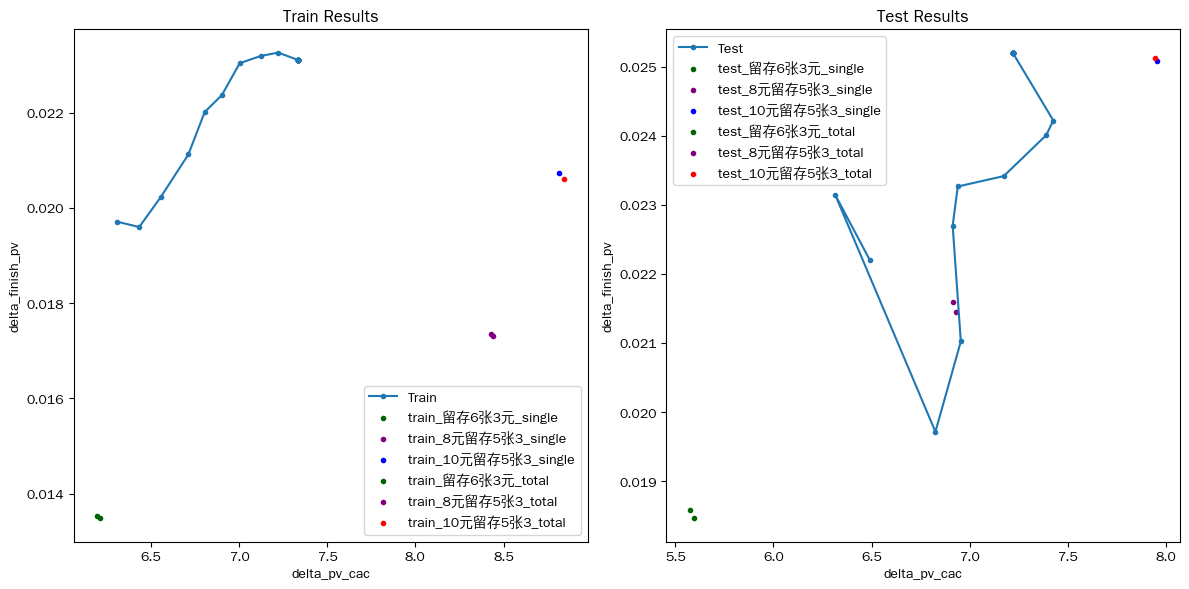

In [29]:
# 不使用笛卡尔积
# train_df3, val_df3, bucket_mapping13, reverse_mapping3, processed_data3, next_processed_data3, discount_res_list3, discount_res_test_list3,train_list1, test_list3, tongbu_list3, tongbu_all_list3 = main_try(train_move_bucketing3, val_move_bucketing3, group_name_list, control_name='DS空白',cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=False,show_tongbu=True,combinations=False)
outputs = main_try(
    train_bucketing,
    val_bucketing,
    group_name_list,
    control_name='DS空白',
    cost_list=cost_list,
    all_columns=all_columns,
    stages=stages,
    discount_para=discount_para,
    method=0,
    read_directly=False,
    show_tongbu=True,
    combinations=False,
    simulation_flag=True,
)
(train_df,val_df,bucket_mapping,reverse_mapping,processed_data,next_processed_data,discount_res_list,
 discount_res_test_list,train_list,test_list,tongbu_list,tongbu_all_list,) = outputs

In [30]:
test_result_df = pd.DataFrame(
    test_list,
    columns=[
        'set_cac', # OR-Tools 输入的 CAC 约束
        'sim_delta_pv_cac', # 验证集仿真出来的实际增量 PV CAC
        'sim_delta_pv_per_user', # 验证集仿真人均增量完单 PV
        'sim_delta_uv_per_user', # 验证集仿真人均增量完单 UV
        'pv_uv_ratio',
    ]
)

test_result_df

,set_cac,sim_delta_pv_cac,sim_delta_pv_per_user,sim_delta_uv_per_user,pv_uv_ratio
0,6.5,6.490838,0.022200,0.007943,2.795096
1,6.6,6.314157,0.023146,0.008116,2.851976
2,6.7,6.825215,0.019716,0.007155,2.755640
3,6.8,6.954595,0.021022,0.007648,2.748851
4,6.9,6.913079,0.022697,0.008111,2.798115
5,7.0,6.939129,0.023264,0.008232,2.826036
6,7.1,7.173402,0.023414,0.008406,2.785363
7,7.2,7.389512,0.024006,0.008511,2.820652
8,7.3,7.425885,0.024219,0.008685,2.788498
9,7.4,7.218762,0.025201,0.008874,2.839997


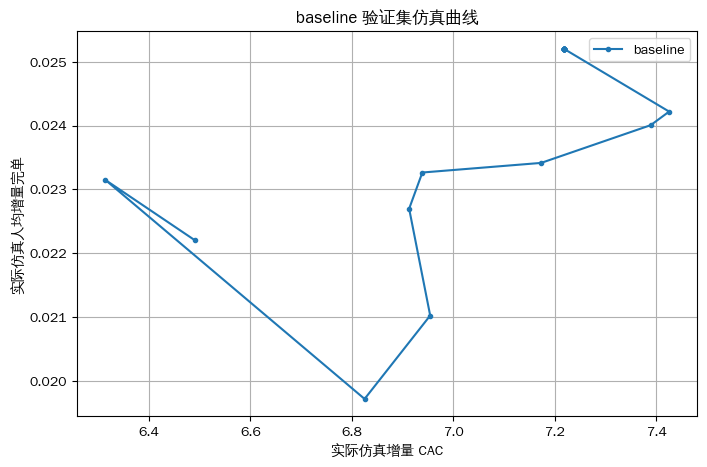

In [31]:
plt.figure(figsize=(8, 5))
plt.plot(
    test_result_df['sim_delta_pv_cac'],
    test_result_df['sim_delta_pv_per_user'],
    marker='.',
    label=scheme_name
)

plt.xlabel('实际仿真增量 CAC')
plt.ylabel('实际仿真人均增量完单')
plt.title(f'{scheme_name} 验证集仿真曲线')
plt.legend()
plt.grid(True)
plt.show()

In [26]:
# 三方案对比

In [34]:
scheme_dfs = {
    'baseline': v1,
    'no_sirius': v2,
    'replace_order': v3,
}

train_dates = ['2026-06-29'] * 7
val_dates = ['2026-06-30', '2026-07-01', '2026-07-02', '2026-07-03', '2026-07-04', '2026-07-05', '2026-07-06']

# 分桶字段：65 可以只参与分桶，不参与运筹
columns = ['cost_1', 'left1053','left853', 'left63','left1053_minus_left63','left853_minus_left63']

all_columns = ['cost_1_per', 'left1053_per', 'left853_per', 'left63_per', 'left1053_minus_left63_per','left853_minus_left63_per'] 



# 运筹候选动作
opt_group_name_list = ['DS空白', '留存6张3元', '8元留存5张3', '10元留存5张3']

discount_para = {
    'DS空白': 0,
    '留存6张3元': 1,
    '8元留存5张3': 2,
    '10元留存5张3': 3,
}

cost_list = np.arange(6.5, 9.0, 0.1)

stages = [
    (['cost_1_per', 'left1053_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['cost_1_per','left1053_minus_left63_per','left63_per'], 15000),
    (['left853_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] 

results = {}


========== running baseline ==========
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-04']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-05']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-06']
(771181, 44) (816948, 44)
['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....


,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,0.1,37027
4444,0.5,0.5,0.5,0.5,18267
5555,0.6,0.6,0.6,0.6,27112
6666,0.7,0.7,0.7,0.7,37651
7777,0.8,0.8,0.8,0.8,35515
8888,0.9,0.9,0.9,0.9,36909
9999,1.0,1.0,1.0,1.0,60222


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
10,0.1,0.2,0.1,18357
111,0.2,0.2,0.2,25169
121,0.2,0.3,0.2,17809
212,0.3,0.2,0.3,15879
222,0.3,0.3,0.3,21244
333,0.4,0.4,0.4,21273


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,21449
1,0.2,34209
2,0.3,40004
3,0.4,20399
6,0.7,39421
7,0.8,24748



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
4,0.5,16568
5,0.6,12227
8,0.9,5668
9,1.0,16684


[ 6 28 12  0  2 16 27  4 21 25  1 15 18 24 22  8  7 19 26  3 14  5 20 10
  9 23 11 17 13]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   4856        7.0       20.0      52.620   
1              0   8元留存5张3   4950        2.0       19.0      55.711   
2              0      DS空白  19882       20.0       80.0       0.000   
3              0    留存6张3元   7339        7.0       23.0      65.032   
4              1  10元留存5张3   2326       20.0       76.0     195.440   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   4840       52.0      137.0     446.970   
112           28  10元留存5张3   6324      180.0      516.0    2144.179   
113           28   8元留存5张3   6793      188.0      540.0    2052.510   
114           28      DS空白  27960      462.0     1182.0      70.292   
115           28    留存6张3元  10070      253.0      647.0    1778.233   

     delta_cvr   delta_cac  
0     0.00009

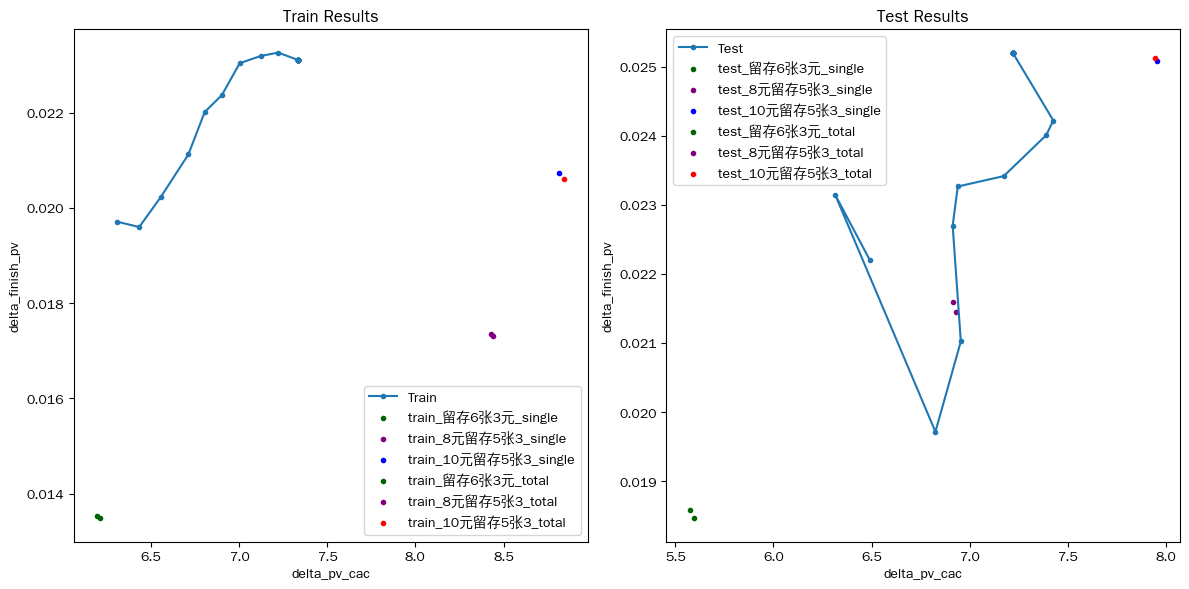


========== running no_sirius ==========
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-04']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-05']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-06']
(771181, 44) (816948, 44)
['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
5555,0.6,0.6,0.6,0.6,15545
6666,0.7,0.7,0.7,0.7,27801
7777,0.8,0.8,0.8,0.8,32049
8788,0.9,0.8,0.9,0.9,17563
8888,0.9,0.9,0.9,0.9,35650
9999,1.0,1.0,1.0,1.0,54934


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
444,0.5,0.5,0.5,19848
989,1.0,0.9,1.0,15383


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,27457
8,0.9,23885



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
1,0.2,13625
2,0.3,13665
3,0.4,15301
4,0.5,13830
5,0.6,12002
6,0.7,7726
7,0.8,17632
9,1.0,6433


[ 5 24 10  1  6 16 15 23 22 13 14  4 18  8 11 21 12  3 20 19  2 17  7  9
  0]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   1977       10.0       24.0     130.803   0.002832   
1             0   8元留存5张3   1981       18.0       42.0     189.893   0.011894   
2             0      DS空白   8595       26.0       80.0       0.000        NaN   
3             0    留存6张3元   2992       19.0       48.0     127.038   0.006735   
4             1  10元留存5张3   3583       33.0       66.0     413.620   0.011370   
..          ...       ...    ...        ...        ...         ...        ...   
95           23    留存6张3元   4642      122.0      250.0     614.543   0.016464   
96           24  10元留存5张3  12451      161.0      433.0    1742.950   0.010813   
97           24   8元留存5张3  12883      160.0      447.0    1453.062   0.010733   
98           24      DS空白  55584      467.0     1332.0      80.313        NaN   
99           24 

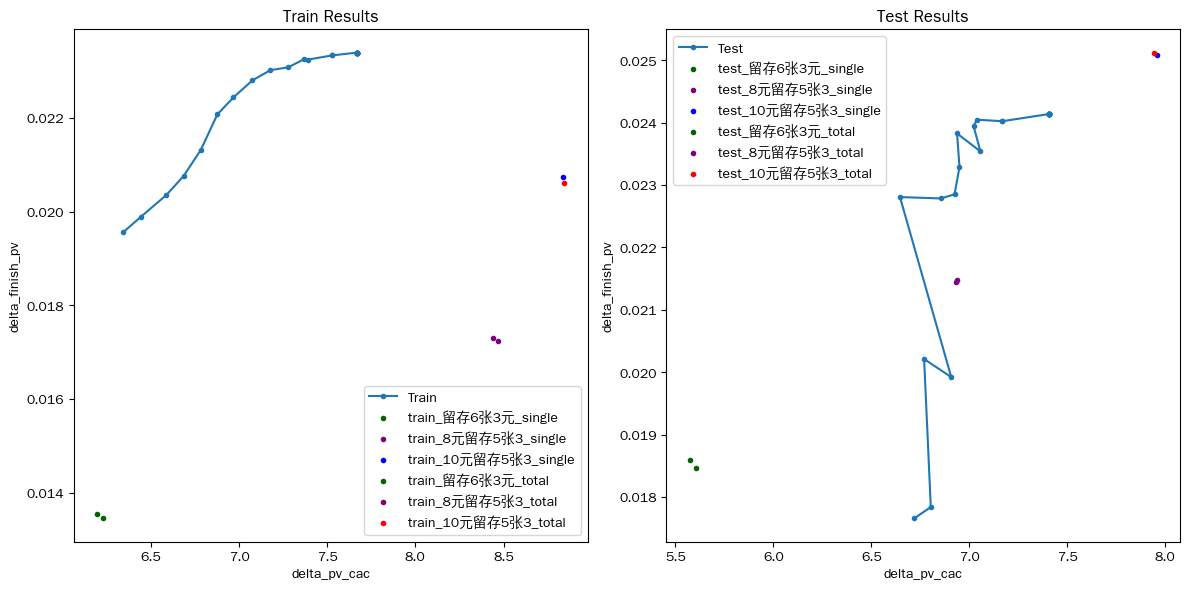


========== running replace_order ==========
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-04']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-05']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-06']
(771181, 44) (816948, 44)
['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
6666,0.7,0.7,0.7,0.7,17855
7677,0.8,0.7,0.8,0.8,15288
7777,0.8,0.8,0.8,0.8,20909
8788,0.9,0.8,0.9,0.9,16837
8888,0.9,0.9,0.9,0.9,23903
9899,1.0,0.9,1.0,1.0,17559
9999,1.0,1.0,1.0,1.0,45809


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,16167


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,25387
6,0.7,22873



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
1,0.2,4059
2,0.3,10609
3,0.4,13826
4,0.5,13169
5,0.6,16476
7,0.8,18264
8,0.9,18130
9,1.0,13444


[25  6 15  8 22 18 28 16 27 19  3 12 13 26 10 21  9  5 20 24 14  0  2 23
  4  7  1 11 17]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2252       12.0       18.0     170.358   
1              0   8元留存5张3   2280       20.0       39.0     194.855   
2              0      DS空白   9931       32.0       77.0      20.162   
3              0    留存6张3元   3392       35.0       77.0     283.189   
4              1  10元留存5张3   1940       26.0       68.0     281.828   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   4454       46.0      130.0     339.769   
112           28  10元留存5张3  13799      261.0      666.0    2998.132   
113           28   8元留存5张3  13913      216.0      535.0    2120.119   
114           28      DS空白  59436      602.0     1586.0     195.443   
115           28    留存6张3元  20829      329.0      824.0    1941.930   

     delta_cvr   delta_cac  
0     0.00023

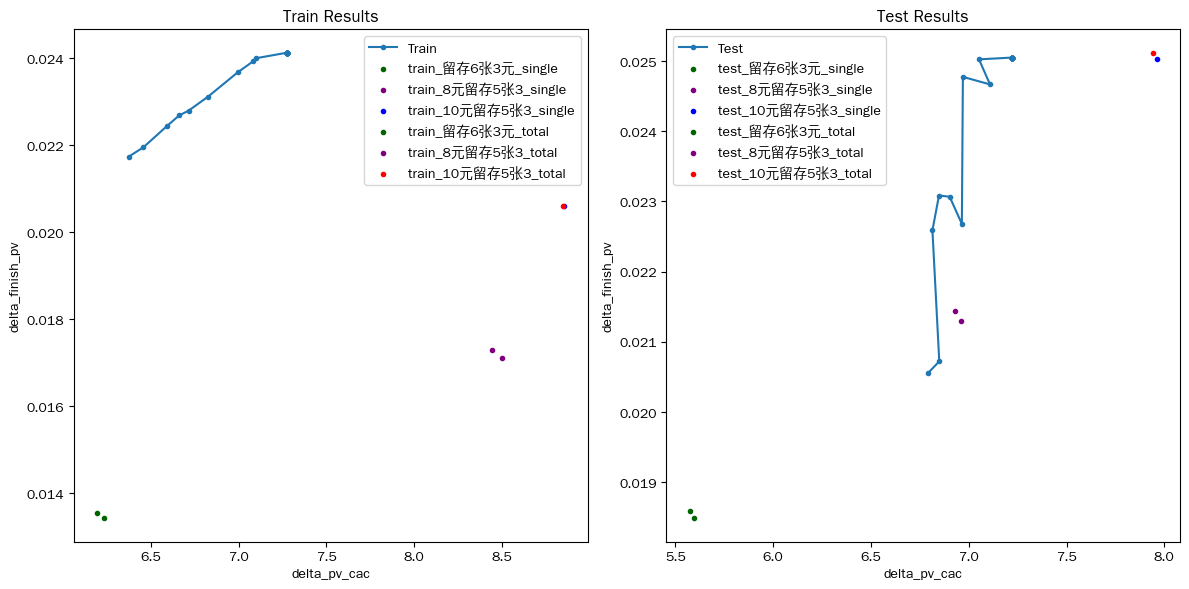

In [35]:
for scheme_name, data_df in scheme_dfs.items():
    print(f'\n========== running {scheme_name} ==========')

    quantile_thresholds, train_bucketing, val_bucketing = move_threshold_main(
        data_df.copy(),
        opt_group_name_list,
        columns,
        train_dates,
        val_dates
    )

    outputs = main_try(
        train_bucketing,
        val_bucketing,
        opt_group_name_list,
        control_name='DS空白',
        cost_list=cost_list,
        all_columns=all_columns,
        stages=stages,
        discount_para=discount_para,
        method=0,
        read_directly=False,
        show_tongbu=True,
        combinations=False,
        simulation_flag=True,
    )

    results[scheme_name] = {
        'quantile_thresholds': quantile_thresholds,
        'train_df': outputs[0],
        'val_df': outputs[1],
        'bucket_mapping': outputs[2],
        'reverse_mapping': outputs[3],
        'processed_data': outputs[4],
        'next_processed_data': outputs[5],
        'discount_res_list': outputs[6],
        'discount_res_test_list': outputs[7],
        'train_list': outputs[8],
        'test_list': outputs[9],
        'tongbu_list': outputs[10],
        'tongbu_all_list': outputs[11],
    }

In [36]:
def build_result_df(result_list, scheme_name, data_type):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr', # 人均增量完单 PV = 增量完单量 / 仿真人数
            '实际增量首单cvr',# 人均增量完单 UV = 增量完单用户数 / 仿真人数,“是否有首个完单/是否转化”的用户数
            '留存频次',
        ]
    )
    df['scheme'] = scheme_name
    df['data_type'] = data_type
    return df


summary_list = []

for scheme_name, res in results.items():
    summary_list.append(build_result_df(res['train_list'], scheme_name, 'train'))
    summary_list.append(build_result_df(res['test_list'], scheme_name, 'test'))

summary_df = pd.concat(summary_list, ignore_index=True)

summary_df[
    ['scheme', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,scheme,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,baseline,train,6.5,6.305133,0.019712,0.007275,2.709688
1,baseline,train,6.6,6.433638,0.019597,0.007226,2.711842
2,baseline,train,6.7,6.557600,0.020235,0.007215,2.804683
3,baseline,train,6.8,6.712413,0.021120,0.007082,2.982405
4,baseline,train,6.9,6.804970,0.022010,0.007525,2.924794
...,...,...,...,...,...,...,...
145,replace_order,test,8.5,7.222666,0.025050,0.009025,2.775546
146,replace_order,test,8.6,7.222666,0.025050,0.009025,2.775546
147,replace_order,test,8.7,7.222666,0.025050,0.009025,2.775546
148,replace_order,test,8.8,7.222666,0.025050,0.009025,2.775546


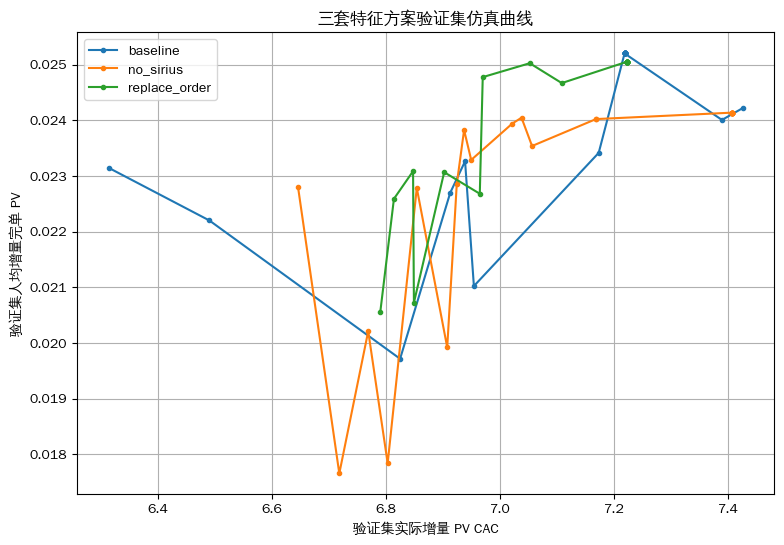

In [44]:
plt.figure(figsize=(9, 6))

for scheme_name in results.keys():
    plot_df = summary_df[
        (summary_df['scheme'] == scheme_name) &
        (summary_df['data_type'] == 'test')
     ].sort_values('实际增量cac')
   #   ].sort_values('约束cac')   # 按约束 cac 顺序连线

    plt.plot(
        plot_df['实际增量cac'],
        plot_df['实际增量cvr'],
        marker='.',
        label=scheme_name
    )

plt.xlabel('验证集实际增量 PV CAC')
plt.ylabel('验证集人均增量完单 PV')
plt.title('三套特征方案验证集仿真曲线')
plt.legend()
plt.grid(True)
plt.show()

In [25]:
# 多个stage参数

In [26]:
scheme_dfs = {
    'baseline': v1,
    'no_sirius': v2,
    'replace_order': v3,
}

train_dates = ['2026-06-29'] * 7

val_dates = ['2026-06-30','2026-07-01','2026-07-02','2026-07-03', '2026-07-04','2026-07-05','2026-07-06']

# 1053 参与决策
opt_group_name_list = [
    'DS空白',
    '留存6张3元',
    '8元留存5张3',
    '10元留存5张3',
]

discount_para = {
    'DS空白': 0,
    '留存6张3元': 1,
    '8元留存5张3': 2,
    '10元留存5张3': 3,
}

cost_list = np.arange(6.5, 9.0, 0.1)

In [27]:

# 2. 自动从 stage 推导 columns / all_columns

def get_all_columns_from_stages(stages):
    all_cols = []
    for stage_cols, _ in stages:
        for col in stage_cols:
            if col not in all_cols:
                all_cols.append(col)
    return all_cols


def get_raw_columns_from_all_columns(all_columns):
    raw_cols = []
    for col in all_columns:
        if col.endswith('_per'):
            raw_cols.append(col[:-4])
        else:
            raw_cols.append(col)
    return raw_cols


def to_per_cols(raw_cols):
    return [f'{col}_per' for col in raw_cols]

In [28]:

# 3. 多套 stage 方案
# 只从你列出的字段中选：
# left853_minus_left63, left65_minus_left63, left65_minus_left853,
# left1053_minus_left63, left1053_minus_left853, left1053_minus_left65,
# cost_1, cost_2, cost_3, cost_4

stage_configs = {
    # 方案1：当前主线，围绕 1053/853 相对 63 的增益差异 + 63券成本
    's1': [
        (to_per_cols(['cost_1', 'left1053_minus_left63', 'left853_minus_left63','left63']), 15000),
        (to_per_cols(['cost_1','left1053_minus_left63', 'left63']), 15000),
        (to_per_cols(['left853_minus_left63', 'left63']), 15000),
        (to_per_cols(['left63']), 20000),
    ],

    # 方案2：强化 1053 与 853 的区分，适合判断“强券1053是否值得替代853”
    's2': [
        (to_per_cols(['cost_1', 'left1053_minus_left63', 'left853_minus_left63','left63']), 15000),
        (to_per_cols(['cost_1','left853_minus_left63', 'left63']), 15000),
        (to_per_cols(['left1053_minus_left63', 'left63']), 15000),
        (to_per_cols(['left63']), 20000),
    ],
    

    # 方案3：同时看 1053 相对 63、1053 相对 853，偏强券决策
    's3': [
        (to_per_cols(['cost_4', 'left1053_minus_left853','left853_minus_left63','left63']), 15000),
        (to_per_cols(['cost_4','left1053_minus_left853','left63']), 15000),
        (to_per_cols(['left853_minus_left63', 'left63']), 15000),
        (to_per_cols(['left63']), 20000),
    ],
    
     's4': [
        (to_per_cols(['cost_1', 'left1053_minus_left853', 'left1053_minus_left63','left853_minus_left63','left63']), 15000),
        (to_per_cols(['cost_1','left1053_minus_left63', 'left853_minus_left63','left63']), 15000),
        (to_per_cols(['left853_minus_left63', 'left63']), 15000),
        (to_per_cols(['left63']), 20000),
    ]
  
}


========== running baseline | s1 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_1_per', 'left1053_minus_left63_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27',

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,0.1,37027
4444,0.5,0.5,0.5,0.5,18267
5555,0.6,0.6,0.6,0.6,27112
6666,0.7,0.7,0.7,0.7,37651
7777,0.8,0.8,0.8,0.8,35515
8888,0.9,0.9,0.9,0.9,36909
9999,1.0,1.0,1.0,1.0,60222


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
10,0.1,0.2,0.1,18357
111,0.2,0.2,0.2,25169
121,0.2,0.3,0.2,17809
212,0.3,0.2,0.3,15879
222,0.3,0.3,0.3,21244
333,0.4,0.4,0.4,21273


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,21449
1,0.2,34209
2,0.3,40004
3,0.4,20399
6,0.7,39421
7,0.8,24748



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
4,0.5,16568
5,0.6,12227
8,0.9,5668
9,1.0,16684


[ 6 28 12  0  2 16 27  4 21 25  1 15 18 24 23  8  7 19 26  3 14  5 20 10
  9 22 11 17 13]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   4856        7.0       20.0      52.620   
1              0   8元留存5张3   4950        2.0       19.0      55.711   
2              0      DS空白  19882       20.0       80.0       0.000   
3              0    留存6张3元   7339        7.0       23.0      65.032   
4              1  10元留存5张3   2326       20.0       76.0     195.440   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   4840       52.0      137.0     446.970   
112           28  10元留存5张3   6324      180.0      516.0    2144.179   
113           28   8元留存5张3   6793      188.0      540.0    2052.510   
114           28      DS空白  27960      462.0     1182.0      70.292   
115           28    留存6张3元  10070      253.0      647.0    1778.233   

     delta_cvr   delta_cac  
0     0.00009

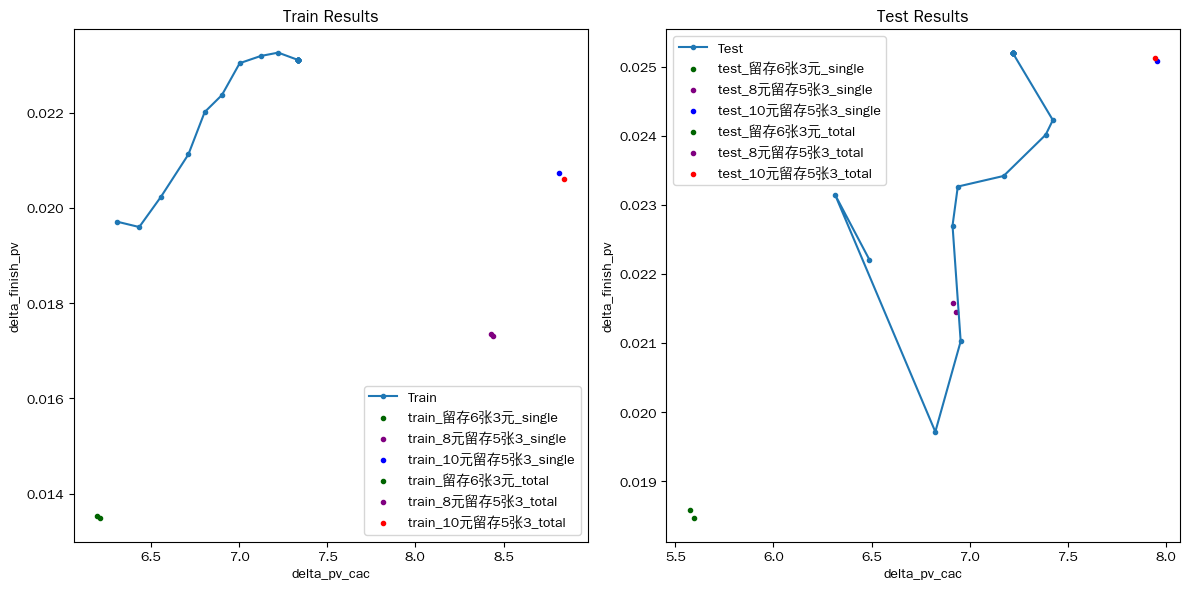


========== running baseline | s2 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_1_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['left1053_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27',

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,0.1,37027
4444,0.5,0.5,0.5,0.5,18267
5555,0.6,0.6,0.6,0.6,27112
6666,0.7,0.7,0.7,0.7,37651
7777,0.8,0.8,0.8,0.8,35515
8888,0.9,0.9,0.9,0.9,36909
9999,1.0,1.0,1.0,1.0,60222


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left853_minus_left63_per,left63_per,counts
10,0.1,0.2,0.1,19916
111,0.2,0.2,0.2,20833
121,0.2,0.3,0.2,18544
212,0.3,0.2,0.3,15933
222,0.3,0.3,0.3,17957
323,0.4,0.3,0.4,16245
333,0.4,0.4,0.4,20460
878,0.9,0.8,0.9,15347


['left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
1,0.2,37810
2,0.3,43237
3,0.4,40669
6,0.7,39421
7,0.8,23645
8,0.9,24849



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,19890
4,0.5,6403
5,0.6,15395
9,1.0,16684


[ 6 27 13  0 26  2 15 25  4 23  1 16 19 22  7  9  8 24  3 12  5 14 17 20
 11 21 10 18]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   4856        7.0       20.0      52.620   
1              0   8元留存5张3   4950        2.0       19.0      55.711   
2              0      DS空白  19882       20.0       80.0       0.000   
3              0    留存6张3元   7339        7.0       23.0      65.032   
4              1  10元留存5张3   2326       20.0       76.0     195.440   
..           ...       ...    ...        ...        ...         ...   
107           26    留存6张3元   4947      143.0      325.0     687.833   
108           27  10元留存5张3   7274      153.0      438.0    1791.908   
109           27   8元留存5张3   7848      168.0      541.0    1798.301   
110           27      DS空白  31925      378.0      989.0      50.292   
111           27    留存6张3元  11325      204.0      556.0    1581.664   

     delta_cvr   delta_cac  
0     0.000095  

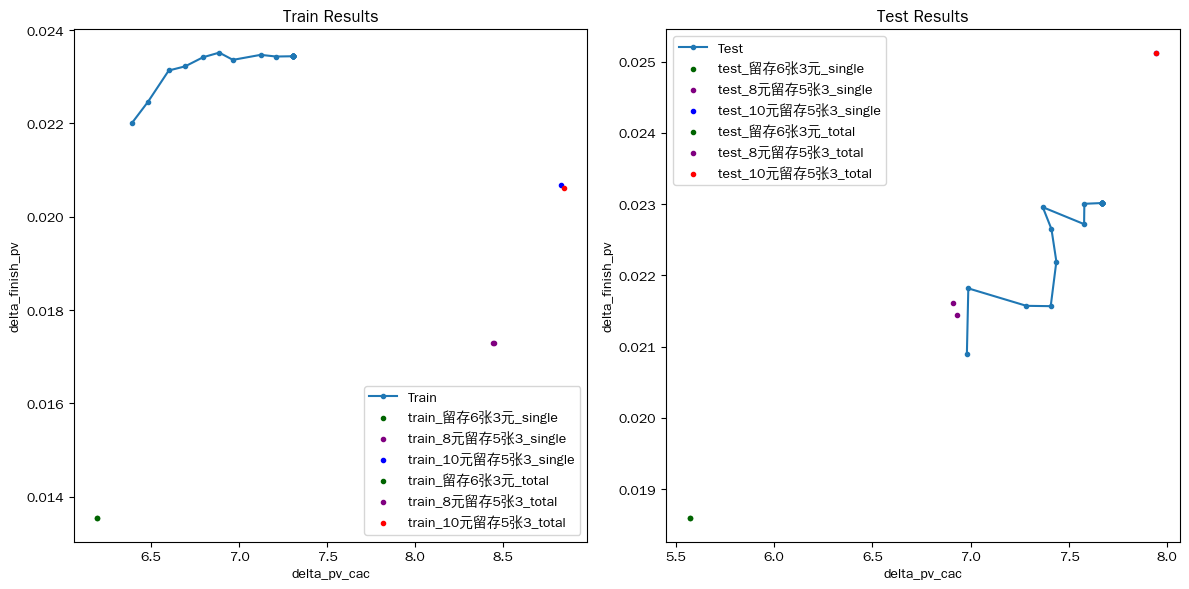


========== running baseline | s3 ==========
columns: ['cost_4', 'left1053_minus_left853', 'left853_minus_left63', 'left63']
all_columns: ['cost_4_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_4_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_4_per', 'left1053_minus_left853_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-

,cost_4_per,left1053_minus_left853_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,0.1,16969
5555,0.6,0.6,0.6,0.6,15046
6666,0.7,0.7,0.7,0.7,25099
7777,0.8,0.8,0.8,0.8,29073
8888,0.9,0.9,0.9,0.9,31611
9999,1.0,1.0,1.0,1.0,52123


['cost_4_per', 'left1053_minus_left853_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_4_per,left1053_minus_left853_per,left63_per,counts
10,0.1,0.2,0.1,15008


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
3,0.4,24041
6,0.7,25804



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,5889
1,0.2,10845
2,0.3,14166
4,0.5,16568
5,0.6,12227
7,0.8,12926
8,0.9,5668
9,1.0,6394


[ 5 29 14 15  1 18  3 25 20 27 17 22  8 11  0 26  9 23 28 21 16 10  4 24
 12  7 13  2 19  6]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2292        3.0        5.0      14.206   
1              0   8元留存5张3   2203        1.0        9.0       6.465   
2              0      DS空白   9092        8.0       36.0       0.000   
3              0    留存6张3元   3382        3.0        8.0      11.883   
4              1  10元留存5张3   1846        8.0       20.0     105.937   
..           ...       ...    ...        ...        ...         ...   
115           28    留存6张3元   5081       62.0      156.0     335.084   
116           29  10元留存5张3  10737      109.0      278.0    1224.896   
117           29   8元留存5张3  10991      122.0      327.0    1221.103   
118           29      DS空白  46406      337.0      930.0      20.757   
119           29    留存6张3元  16549      166.0      395.0    1060.111   

     delta_cvr  delta_cac  
0    -0.001

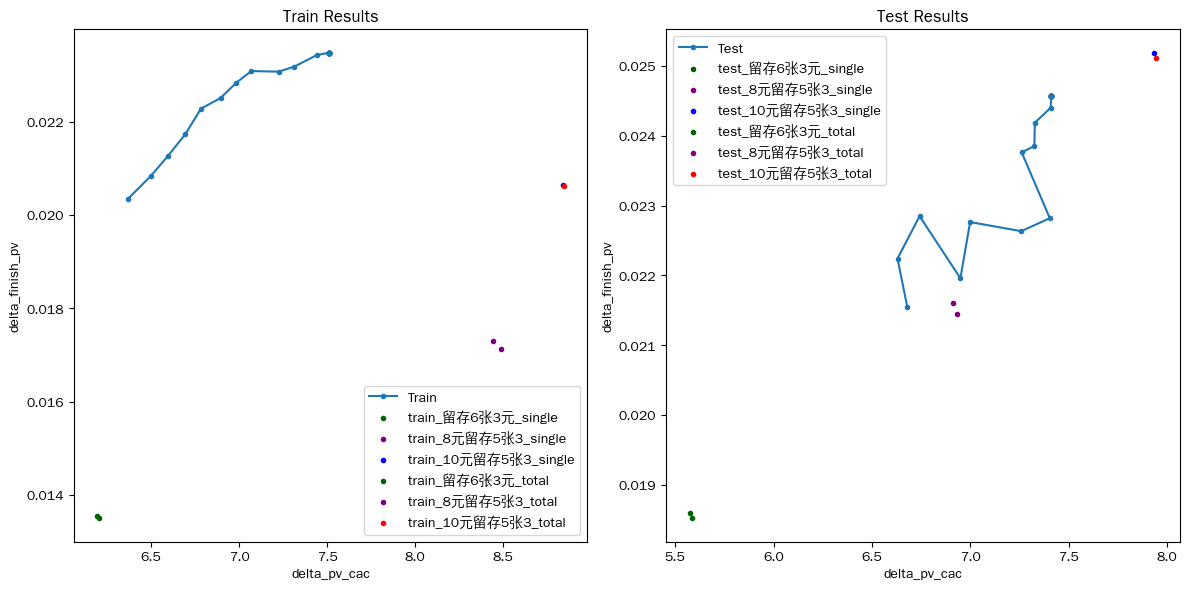


========== running baseline | s4 ==========
columns: ['cost_1', 'left1053_minus_left853', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left853_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_1_per', 'left1053_minus_left853_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27',

,cost_1_per,left1053_minus_left853_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,0.1,0.1,18710
55555,0.6,0.6,0.6,0.6,0.6,15285
66666,0.7,0.7,0.7,0.7,0.7,25302
77777,0.8,0.8,0.8,0.8,0.8,30121
88888,0.9,0.9,0.9,0.9,0.9,31482
99999,1.0,1.0,1.0,1.0,1.0,51992


['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,0.1,18317
4444,0.5,0.5,0.5,0.5,18267


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
3,0.4,24041
6,0.7,25804



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,18408
1,0.2,10845
2,0.3,14166
4,0.5,16568
5,0.6,12227
7,0.8,12926
8,0.9,5668
9,1.0,6394


[ 5 29 15  6  1 18  3 25 27  7 17 20 22  9 11  0 26 10 23 28 21 16 12  4
 24 13  8 14  2 19]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2529        4.0       11.0      16.788   
1              0   8元留存5张3   2435        1.0        9.0       8.116   
2              0      DS空白  10006       11.0       56.0       0.000   
3              0    留存6张3元   3740        3.0        8.0      15.529   
4              1  10元留存5张3   1925       13.0       29.0     140.226   
..           ...       ...    ...        ...        ...         ...   
115           28    留存6张3元   5081       62.0      156.0     335.084   
116           29  10元留存5张3  12306      109.0      278.0    1235.346   
117           29   8元留存5张3  12611      125.0      355.0    1242.190   
118           29      DS空白  53348      350.0      980.0      20.757   
119           29    留存6张3元  18937      170.0      401.0    1094.746   

     delta_cvr  delta_cac  
0    -0.001

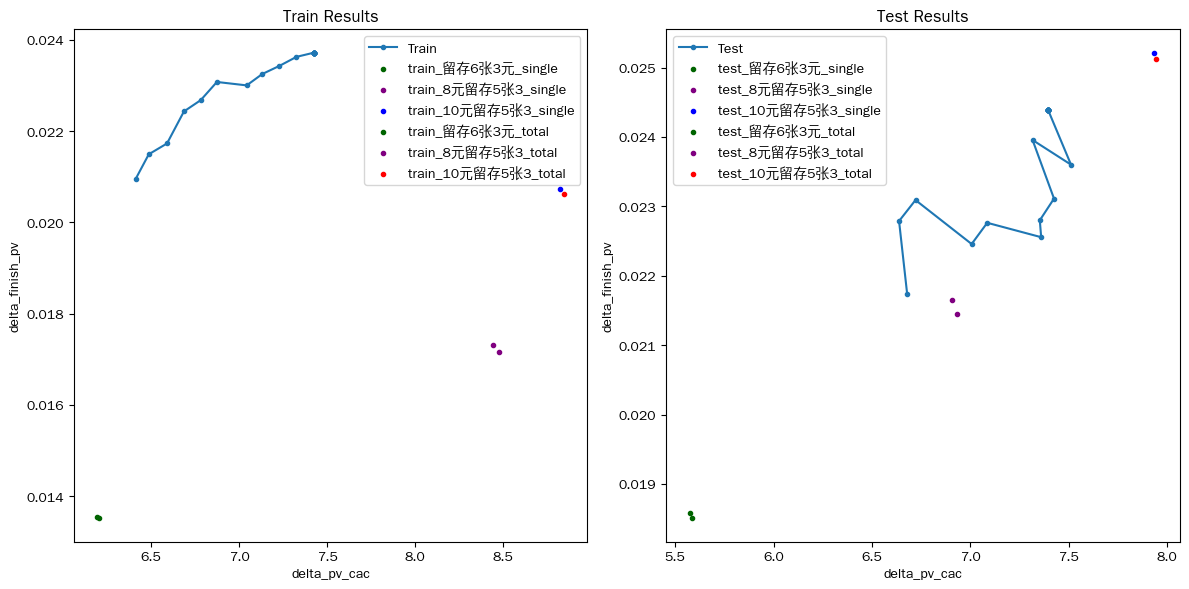


========== running no_sirius | s1 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_1_per', 'left1053_minus_left63_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27'

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
5555,0.6,0.6,0.6,0.6,15545
6666,0.7,0.7,0.7,0.7,27801
7777,0.8,0.8,0.8,0.8,32049
8788,0.9,0.8,0.9,0.9,17563
8888,0.9,0.9,0.9,0.9,35650
9999,1.0,1.0,1.0,1.0,54934


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
444,0.5,0.5,0.5,19848
989,1.0,0.9,1.0,15383


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,27457
8,0.9,23885



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
1,0.2,13625
2,0.3,13665
3,0.4,15301
4,0.5,13830
5,0.6,12002
6,0.7,7726
7,0.8,17632
9,1.0,6433


[ 5 24 10  1  6 16 15 23 22 13 14  4 18  8 11 21 12  3 19 20  2 17  7  9
  0]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   1977       10.0       24.0     130.803   0.002832   
1             0   8元留存5张3   1981       18.0       42.0     189.893   0.011894   
2             0      DS空白   8595       26.0       80.0       0.000        NaN   
3             0    留存6张3元   2992       19.0       48.0     127.038   0.006735   
4             1  10元留存5张3   3583       33.0       66.0     413.620   0.011370   
..          ...       ...    ...        ...        ...         ...        ...   
95           23    留存6张3元   4642      122.0      250.0     614.543   0.016464   
96           24  10元留存5张3  12451      161.0      433.0    1742.950   0.010813   
97           24   8元留存5张3  12883      160.0      447.0    1453.062   0.010733   
98           24      DS空白  55584      467.0     1332.0      80.313        NaN   
99           24 

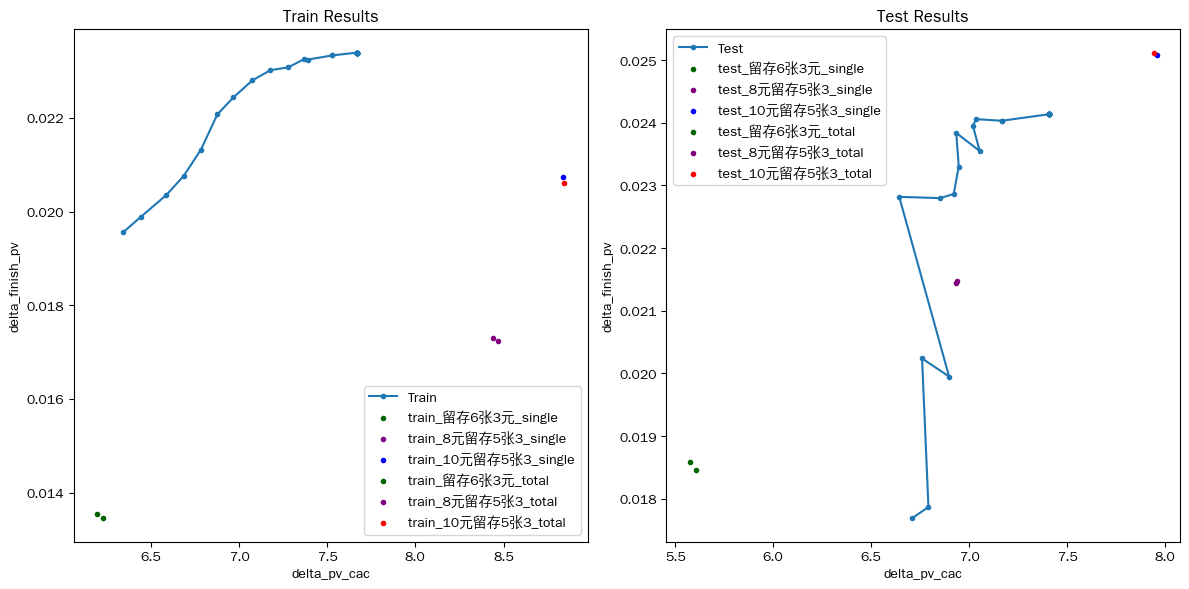


========== running no_sirius | s2 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_1_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['left1053_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27'

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
5555,0.6,0.6,0.6,0.6,15545
6666,0.7,0.7,0.7,0.7,27801
7777,0.8,0.8,0.8,0.8,32049
8788,0.9,0.8,0.9,0.9,17563
8888,0.9,0.9,0.9,0.9,35650
9999,1.0,1.0,1.0,1.0,54934


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,42026
1,0.1,0.1,0.2,15430
111,0.2,0.2,0.2,19598
122,0.2,0.3,0.3,15164
222,0.3,0.3,0.3,16587
233,0.3,0.4,0.4,15182
333,0.4,0.4,0.4,15734
444,0.5,0.5,0.5,16258
545,0.6,0.5,0.6,15816
777,0.8,0.8,0.8,18966


['left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
1,0.2,42098
2,0.3,45367
3,0.4,46398
7,0.8,26085
8,0.9,23885



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,16952
4,0.5,18654
5,0.6,10760
6,0.7,9082
9,1.0,3176


[ 5 24 25  1 13 27 17 28 29 26 12  4 19  8 16 15  9  6  3 22 10  2 18 11
 23 14 21 20  7  0]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1977       10.0       24.0     130.803   
1              0   8元留存5张3   1981       18.0       42.0     189.893   
2              0      DS空白   8595       26.0       80.0       0.000   
3              0    留存6张3元   2992       19.0       48.0     127.038   
4              1  10元留存5张3   3583       33.0       66.0     413.620   
..           ...       ...    ...        ...        ...         ...   
115           28    留存6张3元   4642      122.0      250.0     614.543   
116           29  10元留存5张3   7218      119.0      308.0    1072.784   
117           29   8元留存5张3   7506      119.0      306.0    1044.394   
118           29      DS空白  32508      454.0     1151.0     100.162   
119           29    留存6张3元  11392      207.0      489.0     908.956   

     delta_cvr  delta_cac  
0     0.002

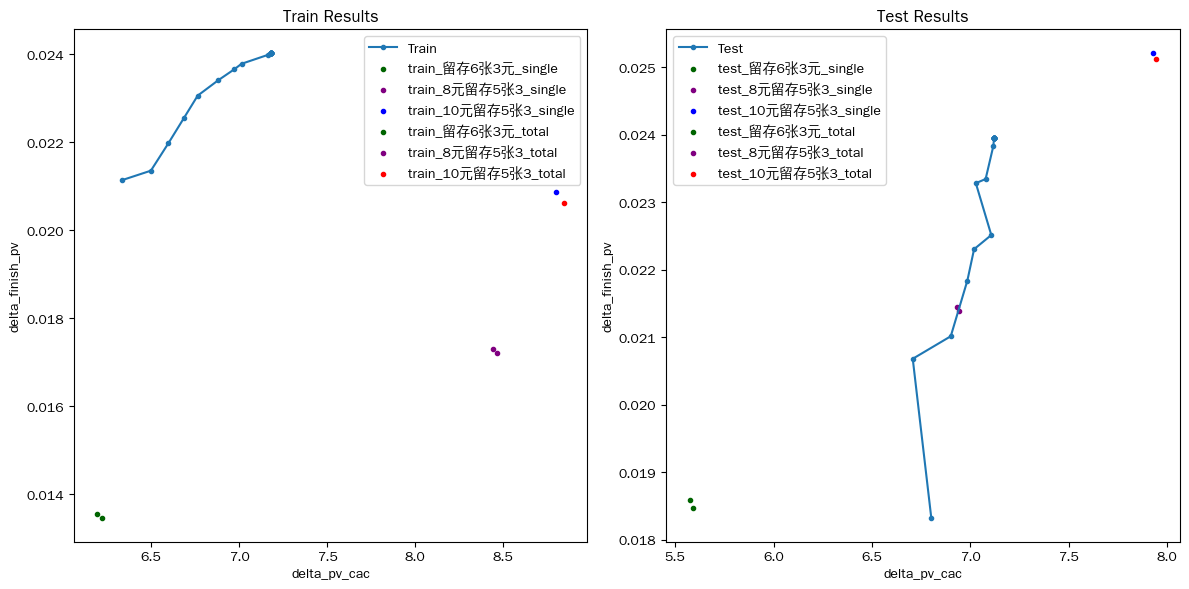


========== running no_sirius | s3 ==========
columns: ['cost_4', 'left1053_minus_left853', 'left853_minus_left63', 'left63']
all_columns: ['cost_4_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_4_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_4_per', 'left1053_minus_left853_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06

,cost_4_per,left1053_minus_left853_per,left853_minus_left63_per,left63_per,counts
600,0.1,0.7,0.1,0.1,19346
7777,0.8,0.8,0.8,0.8,17951
8888,0.9,0.9,0.9,0.9,25460
9999,1.0,1.0,1.0,1.0,41807


['cost_4_per', 'left1053_minus_left853_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_4_per,left1053_minus_left853_per,left63_per,counts
666,0.7,0.7,0.7,15207
787,0.8,0.9,0.8,18109


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,27457



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
1,0.2,13625
2,0.3,13665
3,0.4,15301
4,0.5,17487
5,0.6,12002
6,0.7,6331
7,0.8,14228
8,0.9,11830
9,1.0,5110


[ 3 23  8 18 14 13 20 22 10  7  2 15 11  9 19  6 21  0 17  1 16  5 12  4]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   2622        5.0       11.0      32.177  -0.003129   
1             0   8元留存5张3   2395        6.0       36.0      89.549   0.007707   
2             0      DS空白  10513       15.0       77.0      10.000        NaN   
3             0    留存6张3元   3816        3.0       11.0      30.699  -0.004442   
4             1  10元留存5张3   2176       25.0       48.0     333.322   0.010819   
..          ...       ...    ...        ...        ...         ...        ...   
91           22    留存6张3元   5359      140.0      382.0     629.282   0.000960   
92           23  10元留存5张3  13636      184.0      504.0    2094.229   0.011420   
93           23   8元留存5张3  13986      168.0      452.0    1436.924   0.006777   
94           23      DS空白  60844      541.0     1554.0      80.454        NaN   
95           23    留

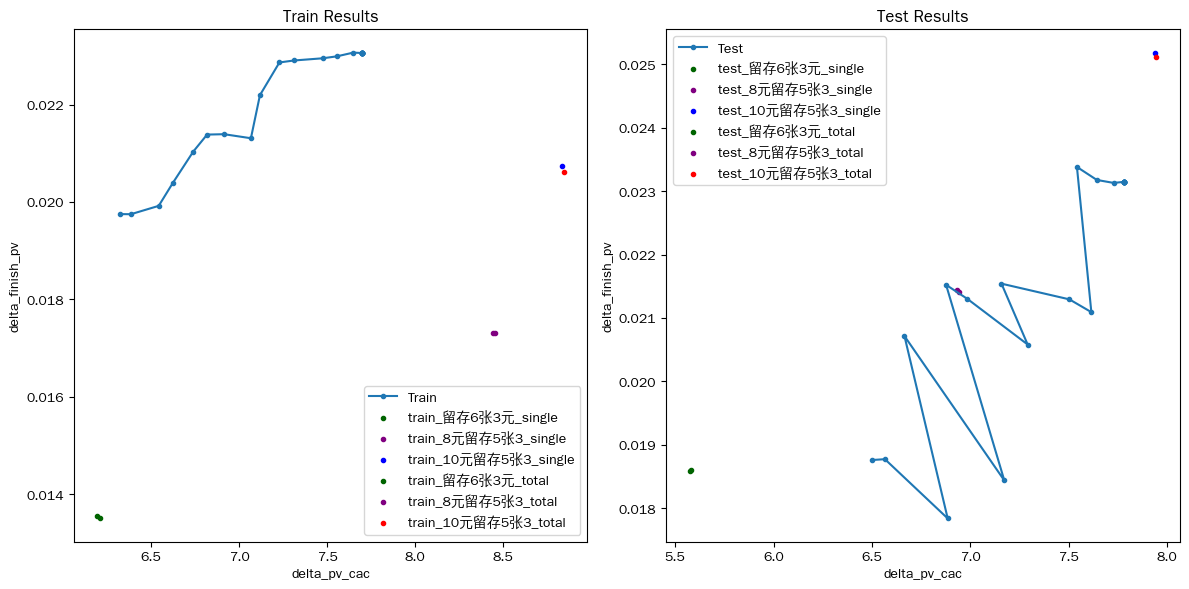


========== running no_sirius | s4 ==========
columns: ['cost_1', 'left1053_minus_left853', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left853_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_1_per', 'left1053_minus_left853_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27'

,cost_1_per,left1053_minus_left853_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
77777,0.8,0.8,0.8,0.8,0.8,16930
88888,0.9,0.9,0.9,0.9,0.9,24282
99999,1.0,1.0,1.0,1.0,1.0,40302


['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
5555,0.6,0.6,0.6,0.6,15545
6666,0.7,0.7,0.7,0.7,27801
7777,0.8,0.8,0.8,0.8,15119
8788,0.9,0.8,0.9,0.9,17563


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,27457



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
1,0.2,13625
2,0.3,13665
3,0.4,15301
4,0.5,17487
5,0.6,12002
6,0.7,7726
7,0.8,17632
8,0.9,11830
9,1.0,5110


[ 2 24  8  4 15 14 21 23 12 13  1 17  7  9 20 10 22  6 18 19  0 16  5 11
  3]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   2058       26.0       51.0     346.912   0.013203   
1             0   8元留存5张3   2132       21.0       51.0     242.186   0.012343   
2             0      DS空白   9414       44.0      109.0      25.151        NaN   
3             0    留存6张3元   3326       32.0       97.0     394.434   0.017586   
4             1  10元留存5张3   3168       57.0      131.0     760.749   0.027088   
..          ...       ...    ...        ...        ...         ...        ...   
95           23    留存6张3元   5359      140.0      382.0     629.282   0.000960   
96           24  10元留存5张3  14245      193.0      527.0    2187.202   0.012020   
97           24   8元留存5张3  14639      178.0      474.0    1526.500   0.007404   
98           24      DS空白  63502      553.0     1586.0      80.454        NaN   
99           24 

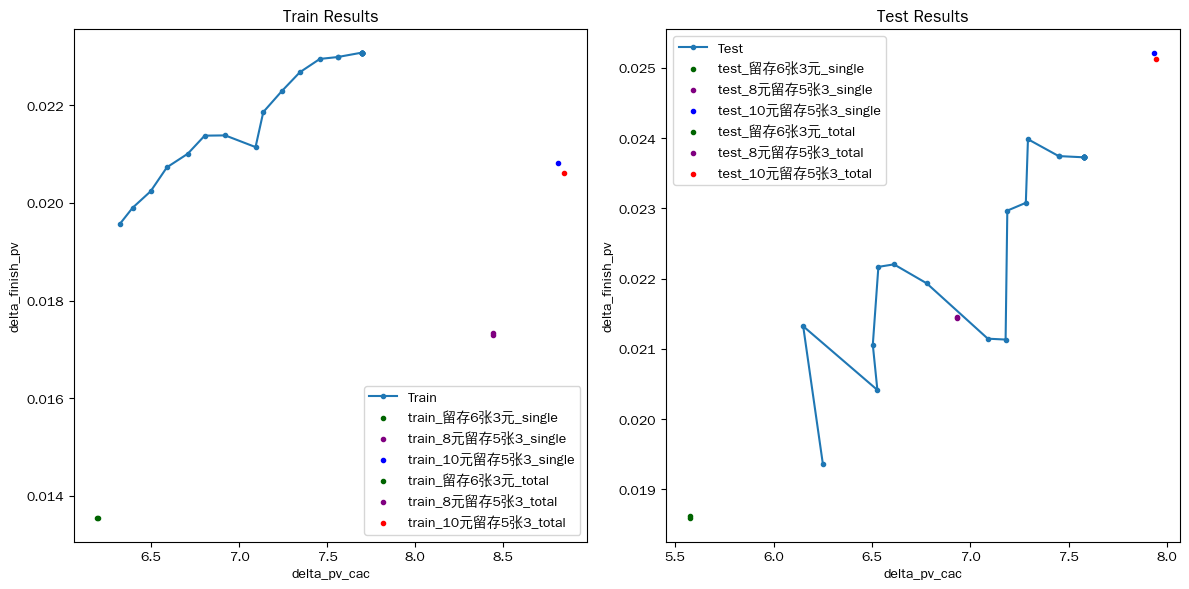


========== running replace_order | s1 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_1_per', 'left1053_minus_left63_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
6666,0.7,0.7,0.7,0.7,17855
7677,0.8,0.7,0.8,0.8,15288
7777,0.8,0.8,0.8,0.8,20909
8788,0.9,0.8,0.9,0.9,16837
8888,0.9,0.9,0.9,0.9,23903
9899,1.0,0.9,1.0,1.0,17559
9999,1.0,1.0,1.0,1.0,45809


['cost_1_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,16167


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,25387
6,0.7,22873



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
1,0.2,4059
2,0.3,10609
3,0.4,13826
4,0.5,13169
5,0.6,16476
7,0.8,18264
8,0.9,18130
9,1.0,13444


[25  6 14 12 22 18 28 16 27 19  3 10 13 26  9 21  8  5 20 24 15  0  2 23
  4  7  1 11 17]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2252       12.0       18.0     170.358   
1              0   8元留存5张3   2280       20.0       39.0     194.855   
2              0      DS空白   9931       32.0       77.0      20.162   
3              0    留存6张3元   3392       35.0       77.0     283.189   
4              1  10元留存5张3   1940       26.0       68.0     281.828   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   4454       46.0      130.0     339.769   
112           28  10元留存5张3  13799      261.0      666.0    2998.132   
113           28   8元留存5张3  13913      216.0      535.0    2120.119   
114           28      DS空白  59436      602.0     1586.0     195.443   
115           28    留存6张3元  20829      329.0      824.0    1941.930   

     delta_cvr   delta_cac  
0     0.00023

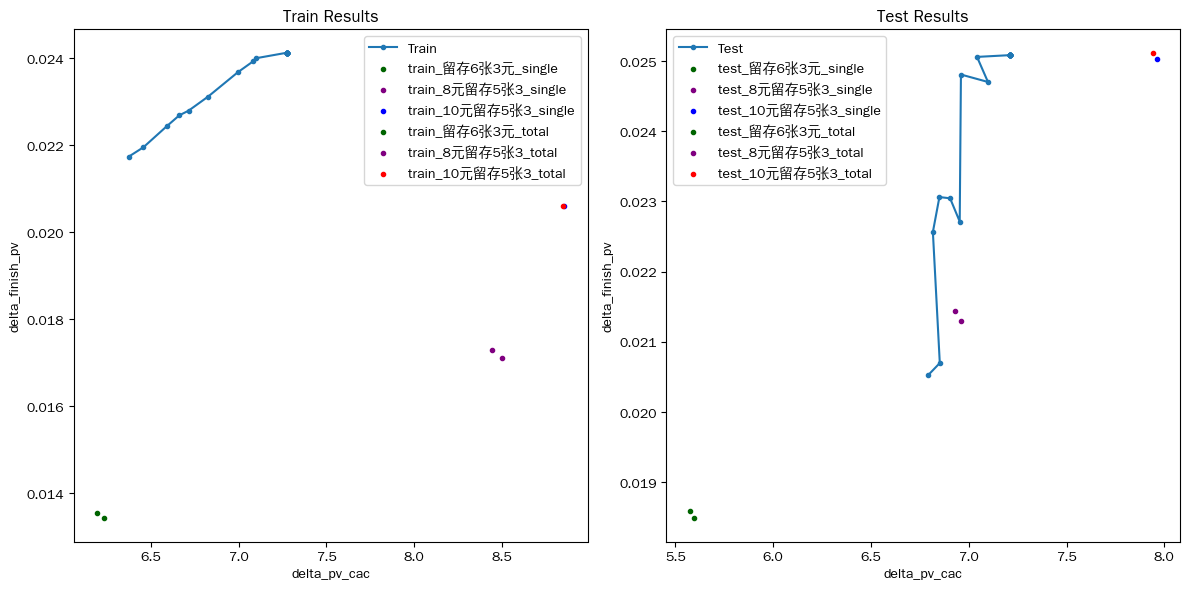


========== running replace_order | s2 ==========
columns: ['cost_1', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_1_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['left1053_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06

,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
6666,0.7,0.7,0.7,0.7,17855
7677,0.8,0.7,0.8,0.8,15288
7777,0.8,0.8,0.8,0.8,20909
8788,0.9,0.8,0.9,0.9,16837
8888,0.9,0.9,0.9,0.9,23903
9899,1.0,0.9,1.0,1.0,17559
9999,1.0,1.0,1.0,1.0,45809


['cost_1_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,0.1,41633
1,0.1,0.1,0.2,15058
111,0.2,0.2,0.2,24944
222,0.3,0.3,0.3,17135
333,0.4,0.4,0.4,15181
444,0.5,0.5,0.5,16612
555,0.6,0.6,0.6,24739
666,0.7,0.7,0.7,18908


['left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,35315
1,0.2,36979
2,0.3,60070
3,0.4,46342
4,0.5,45433
5,0.6,36160
6,0.7,23818
7,0.8,24467
8,0.9,36314



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
9,1.0,13444


[28  6 15  7 25 27 11 29 26 21 12  3 20 16 10 22  9 17  8  5 23 24  0  2
 13  4 14 18  1 19]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2252       12.0       18.0     170.358   
1              0   8元留存5张3   2280       20.0       39.0     194.855   
2              0      DS空白   9931       32.0       77.0      20.162   
3              0    留存6张3元   3392       35.0       77.0     283.189   
4              1  10元留存5张3   1940       26.0       68.0     281.828   
..           ...       ...    ...        ...        ...         ...   
115           28    留存6张3元   7058      163.0      371.0    1050.384   
116           29  10元留存5张3   1652       81.0      199.0     830.530   
117           29   8元留存5张3   1743       76.0      166.0     698.572   
118           29      DS空白   7317      195.0      448.0      20.151   
119           29    留存6张3元   2732      125.0      252.0     561.583   

     delta_cvr   delta_cac  
0     0.00

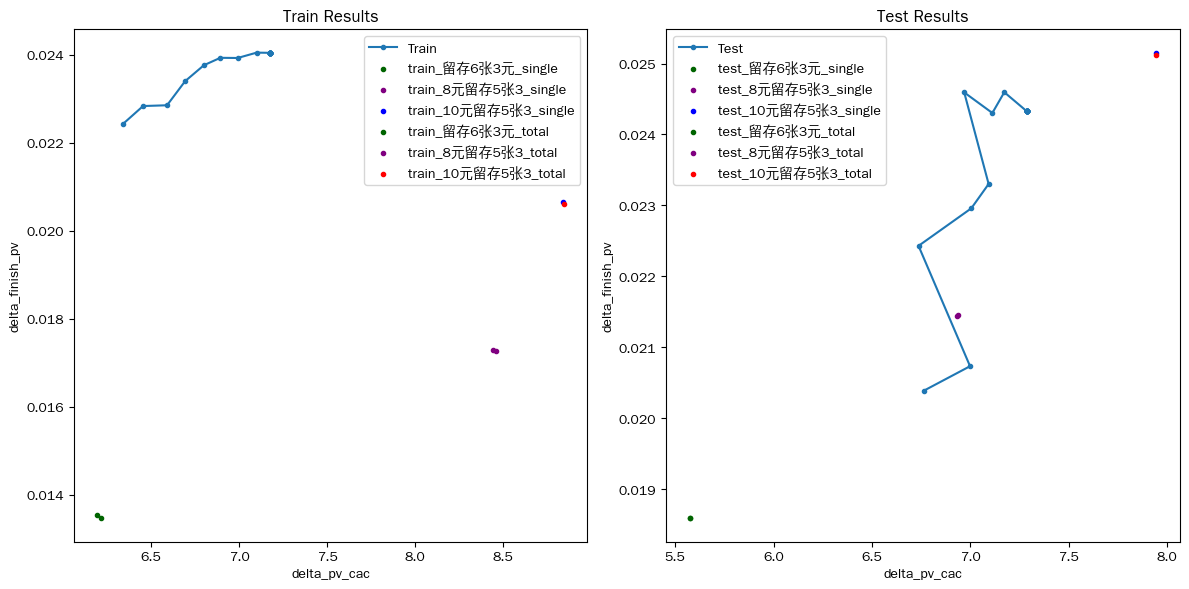


========== running replace_order | s3 ==========
columns: ['cost_4', 'left1053_minus_left853', 'left853_minus_left63', 'left63']
all_columns: ['cost_4_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_4_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_4_per', 'left1053_minus_left853_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-03']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '202

,cost_4_per,left1053_minus_left853_per,left853_minus_left63_per,left63_per,counts
600,0.1,0.7,0.1,0.1,21844
8888,0.9,0.9,0.9,0.9,20173
9999,1.0,1.0,1.0,1.0,30140


['cost_4_per', 'left1053_minus_left853_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_4_per,left1053_minus_left853_per,left63_per,counts
777,0.8,0.8,0.8,16118
787,0.8,0.9,0.8,16710


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,26764
6,0.7,22873



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
1,0.2,4059
2,0.3,10609
3,0.4,13826
4,0.5,13169
5,0.6,16476
7,0.8,11282
8,0.9,18130
9,1.0,9771


[22  2 12  0 19 14 26 13  4 25 16  1 11  8  9 24 23  5 18 10 17  7 20 21
  3  6 15]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2863        1.0        5.0      17.915   
1              0   8元留存5张3   2795        4.0       30.0      63.509   
2              0      DS空白  11884        8.0       30.0       0.000   
3              0    留存6张3元   4302        5.0       15.0      15.987   
4              1  10元留存5张3   2614       43.0       92.0     622.961   
..           ...       ...    ...        ...        ...         ...   
103           25    留存6张3元   4454       46.0      130.0     339.769   
104           26  10元留存5张3  12379      235.0      593.0    2625.434   
105           26   8元留存5张3  12484      202.0      497.0    1959.576   
106           26      DS空白  53653      564.0     1466.0     195.302   
107           26    留存6张3元  18806      308.0      781.0    1787.524   

     delta_cvr  delta_cac  
0    -0.000778  -8.0

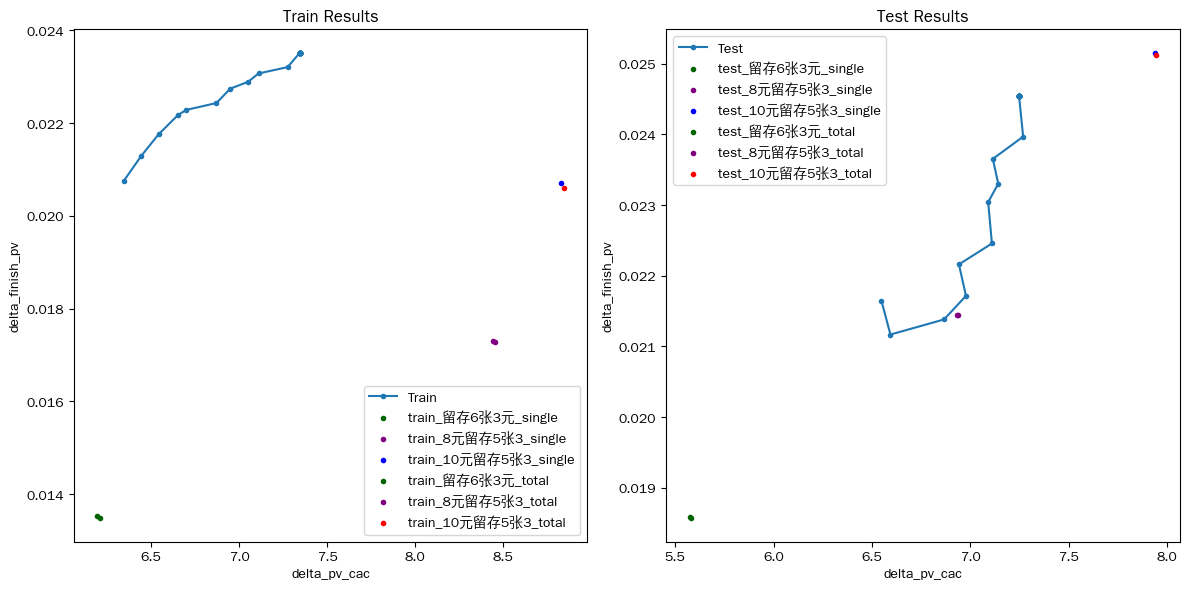


========== running replace_order | s4 ==========
columns: ['cost_1', 'left1053_minus_left853', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['cost_1_per', 'left1053_minus_left853_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['cost_1_per', 'left1053_minus_left853_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000), (['left63_per'], 20000)]
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-06-30']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-01']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27', '2026-06-28', '2026-06-29']
['2026-07-02']
['2026-06-23', '2026-06-24', '2026-06-25', '2026-06-26', '2026-06

,cost_1_per,left1053_minus_left853_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
88888,0.9,0.9,0.9,0.9,0.9,18208
99999,1.0,1.0,1.0,1.0,1.0,28788


['cost_1_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,cost_1_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
6666,0.7,0.7,0.7,0.7,17855
7677,0.8,0.7,0.8,0.8,15288
7777,0.8,0.8,0.8,0.8,20909
8788,0.9,0.8,0.9,0.9,16837
9899,1.0,0.9,1.0,1.0,17559
9999,1.0,1.0,1.0,1.0,17021


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,26764
6,0.7,22873



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
1,0.2,4059
2,0.3,10609
3,0.4,13826
4,0.5,13169
5,0.6,16476
7,0.8,18264
8,0.9,18130
9,1.0,13444


[25  1 15  8 22 18 28 16 27 20  5 12 13 26  7 10 21  9  6 19 24 14  2  4
 23  3 11 17  0]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2343       39.0       84.0     581.228   
1              0   8元留存5张3   2287       47.0      131.0     711.674   
2              0      DS空白   9998       44.0      100.0      40.000   
3              0    留存6张3元   3580       46.0       94.0     411.116   
4              1  10元留存5张3   3620      303.0      697.0    3433.539   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   4454       46.0      130.0     339.769   
112           28  10元留存5张3  13799      261.0      666.0    2998.132   
113           28   8元留存5张3  13913      216.0      535.0    2120.119   
114           28      DS空白  59436      602.0     1586.0     195.443   
115           28    留存6张3元  20829      329.0      824.0    1941.930   

     delta_cvr  delta_cac  
0     0.025849

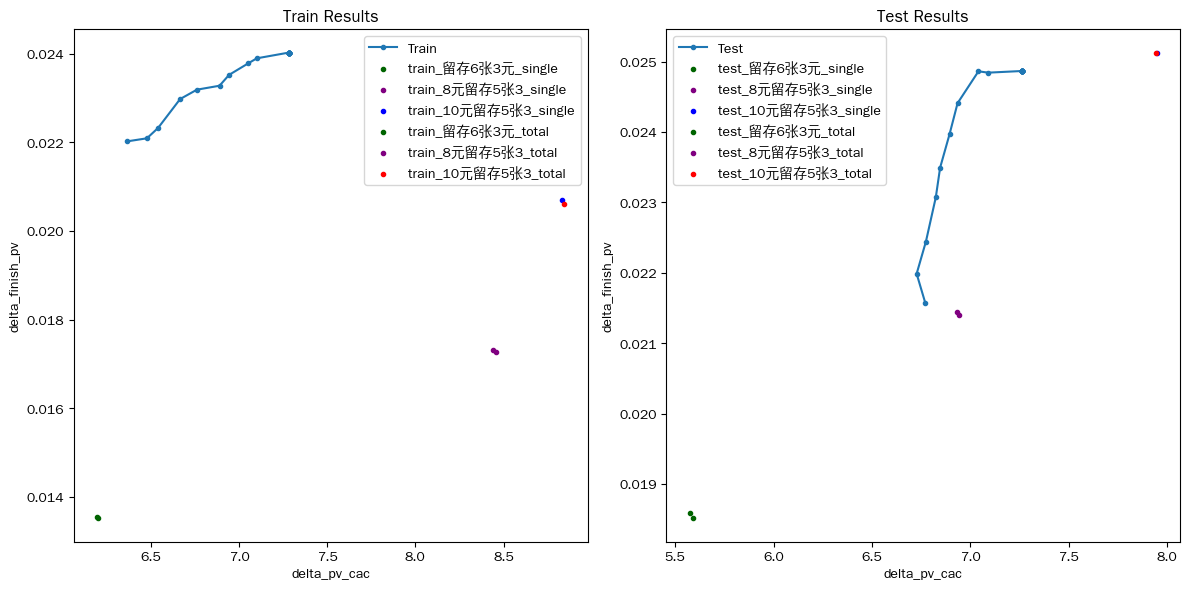

In [29]:

# 4. 多方案 × 多stage 运行
# 注意：main_try(show_tongbu=True) 会每次自动画 Train/Test 图
# 如果你跑 3 * 8 = 24 次，会输出很多图


stage_results = {}

for scheme_name, data_df in scheme_dfs.items():
    for stage_name, stages in stage_configs.items():
        print(f'\n========== running {scheme_name} | {stage_name} ==========')

        all_columns = get_all_columns_from_stages(stages)
        columns = get_raw_columns_from_all_columns(all_columns)

        print('columns:', columns)
        print('all_columns:', all_columns)
        print('stages:', stages)

        quantile_thresholds, train_bucketing, val_bucketing = move_threshold_main(
            data_df.copy(),
            opt_group_name_list,
            columns,
            train_dates,
            val_dates
        )

        outputs = main_try(
            train_bucketing.copy(),
            val_bucketing.copy(),
            opt_group_name_list,
            control_name='DS空白',
            cost_list=cost_list,
            all_columns=all_columns,
            stages=stages,
            discount_para=discount_para,
            method=0,
            read_directly=False,
            show_tongbu=True,
            combinations=False,
            simulation_flag=True,
        )

        stage_results[(scheme_name, stage_name)] = {
            'scheme': scheme_name,
            'stage_name': stage_name,
            'columns': columns,
            'all_columns': all_columns,
            'stages': stages,
            'quantile_thresholds': quantile_thresholds,
            'train_df': outputs[0],
            'val_df': outputs[1],
            'bucket_mapping': outputs[2],
            'reverse_mapping': outputs[3],
            'processed_data': outputs[4],
            'next_processed_data': outputs[5],
            'discount_res_list': outputs[6],
            'discount_res_test_list': outputs[7],
            'train_list': outputs[8],
            'test_list': outputs[9],
            'tongbu_list': outputs[10],
            'tongbu_all_list': outputs[11],
        }

In [30]:

# 5. 汇总 train/test 仿真结果


def build_stage_result_df(result_list, scheme_name, stage_name, data_type):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr',
            '实际增量首单cvr',
            '留存频次',
        ]
    )
    df['scheme'] = scheme_name
    df['stage_name'] = stage_name
    df['data_type'] = data_type
    return df


summary_list = []

for (scheme_name, stage_name), res in stage_results.items():
    summary_list.append(build_stage_result_df(res['train_list'], scheme_name, stage_name, 'train'))
    summary_list.append(build_stage_result_df(res['test_list'], scheme_name, stage_name, 'test'))

stage_summary_df = pd.concat(summary_list, ignore_index=True)

stage_summary_df[
    ['scheme', 'stage_name', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,baseline,s1,train,6.5,6.305133,0.019712,0.007275,2.709688
1,baseline,s1,train,6.6,6.433638,0.019597,0.007226,2.711842
2,baseline,s1,train,6.7,6.557600,0.020235,0.007215,2.804683
3,baseline,s1,train,6.8,6.712413,0.021120,0.007082,2.982405
4,baseline,s1,train,6.9,6.804970,0.022010,0.007525,2.924794
...,...,...,...,...,...,...,...,...
595,replace_order,s4,test,8.5,7.263132,0.024865,0.008992,2.765205
596,replace_order,s4,test,8.6,7.263132,0.024865,0.008992,2.765205
597,replace_order,s4,test,8.7,7.263132,0.024865,0.008992,2.765205
598,replace_order,s4,test,8.8,7.263132,0.024865,0.008992,2.765205


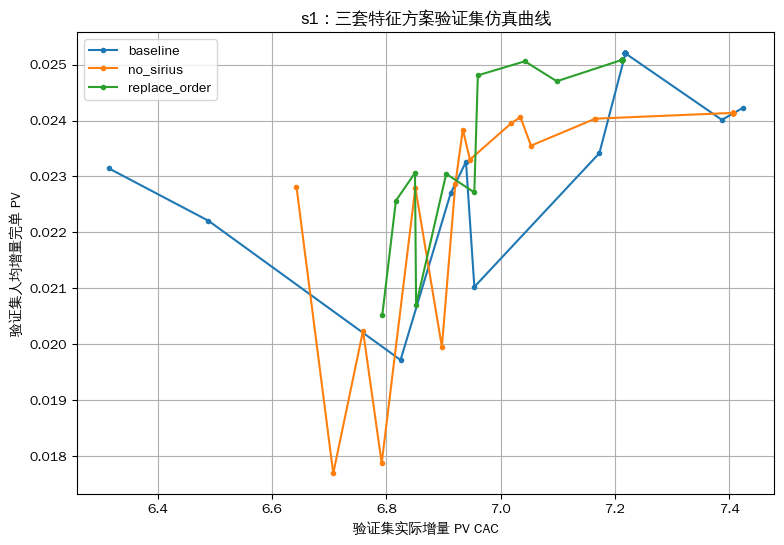

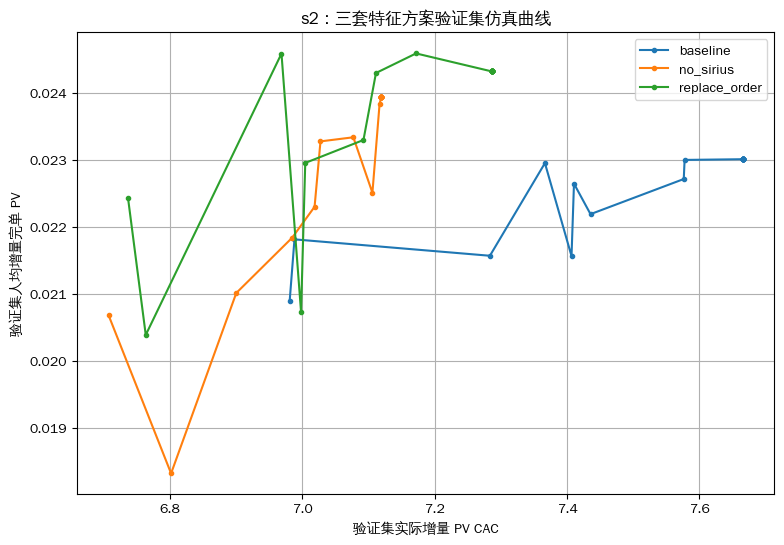

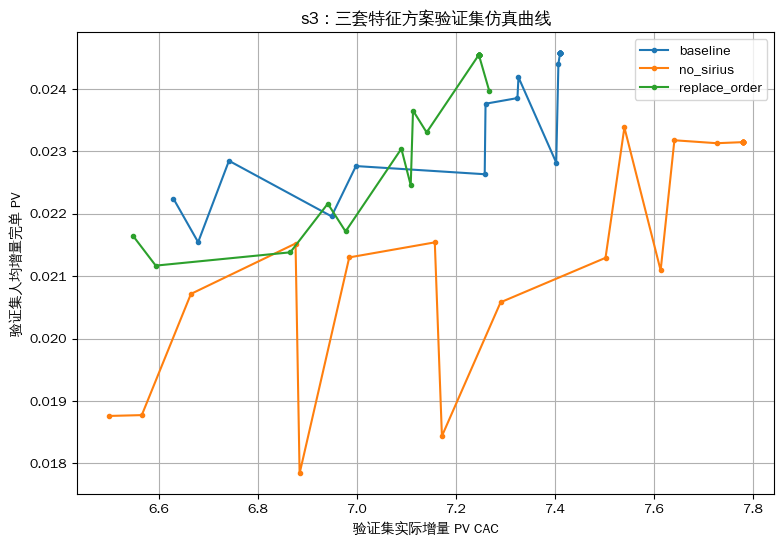

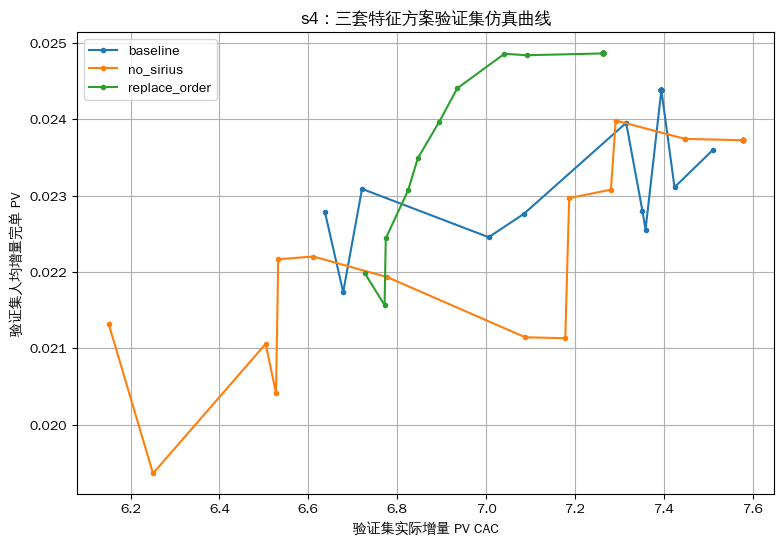

In [40]:

# 6. 一个图对应一个 stage，图里放三个特征方案


for stage_name in stage_configs.keys():
    plt.figure(figsize=(9, 6))

    for scheme_name in scheme_dfs.keys():
        plot_df = stage_summary_df[
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['data_type'] == 'test')
       #  ].sort_values('约束cac')
        ].sort_values('实际增量cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=scheme_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{stage_name}：三套特征方案验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

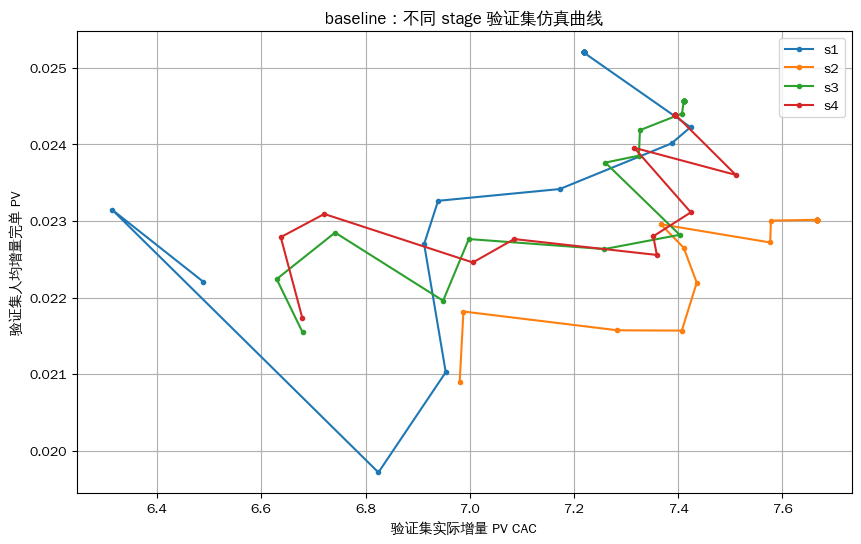

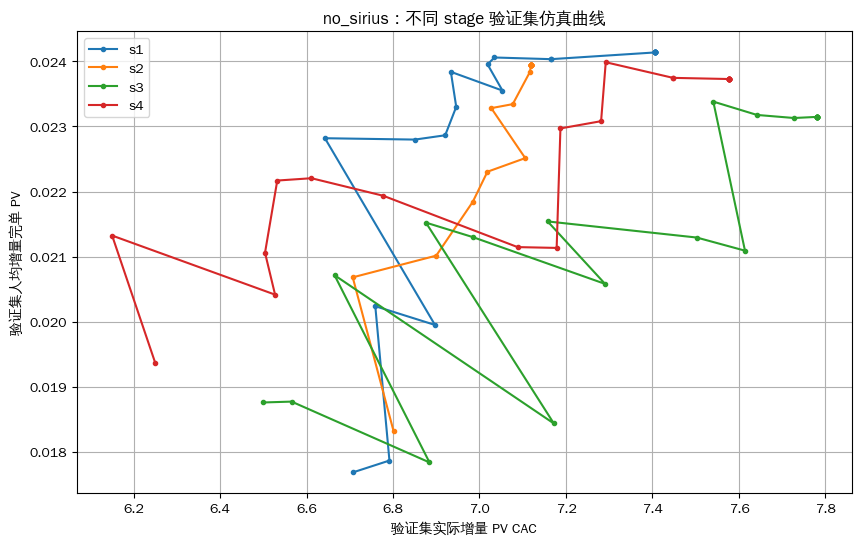

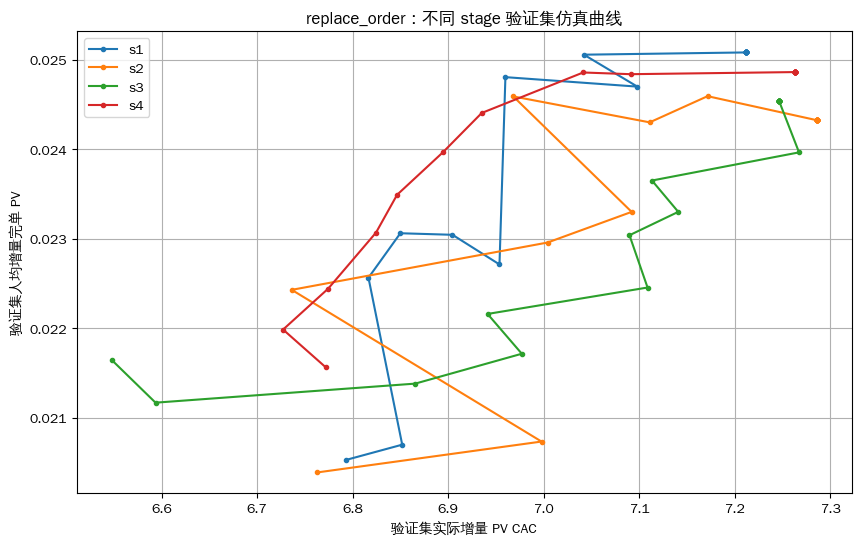

In [32]:

#7. 一个图对应一个方案，图里放不同 stage
for scheme_name in scheme_dfs.keys():
    plt.figure(figsize=(10, 6))

    for stage_name in stage_configs.keys():
        plot_df = stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['data_type'] == 'test')
        ].sort_values('约束cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=stage_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{scheme_name}：不同 stage 验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

In [33]:
test_by_set_cac_df = (
    stage_summary_df[
        (stage_summary_df['stage_name'] == 's1') &
        (stage_summary_df['data_type'] == 'test')
    ]
    .sort_values(['约束cac', 'scheme'])
    [['scheme', 'stage_name', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']]
)

test_by_set_cac_df

,scheme,stage_name,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
25,baseline,s1,6.5,6.488642,0.022206,0.007951,2.792948
225,no_sirius,s1,6.5,6.706982,0.017686,0.006509,2.717034
425,replace_order,s1,6.5,6.792910,0.020527,0.007546,2.720128
26,baseline,s1,6.6,6.313836,0.023146,0.008118,2.851237
226,no_sirius,s1,6.6,6.791766,0.017868,0.006681,2.674431
...,...,...,...,...,...,...,...
248,no_sirius,s1,8.8,7.406453,0.024137,0.008587,2.810962
448,replace_order,s1,8.8,7.212253,0.025085,0.009033,2.776923
49,baseline,s1,8.9,7.218402,0.025201,0.008876,2.839337
249,no_sirius,s1,8.9,7.406453,0.024137,0.008587,2.810962


In [34]:
# 每个约束cac下哪个方案最好
best_each_set_cac = (
    test_by_set_cac_df
    .sort_values(['约束cac', '实际增量cvr'], ascending=[True, False])
    .groupby('约束cac')
    .head(1) )

best_each_set_cac[
    ['约束cac', 'scheme', 'stage_name', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,scheme,stage_name,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
25,6.5,baseline,s1,6.488642,0.022206,0.007951,2.792948
26,6.6,baseline,s1,6.313836,0.023146,0.008118,2.851237
427,6.7,replace_order,s1,6.816640,0.022566,0.008182,2.757959
428,6.8,replace_order,s1,6.850040,0.023063,0.008405,2.743803
429,6.9,replace_order,s1,6.904631,0.023046,0.008481,2.717310
30,7.0,baseline,s1,6.939290,0.023263,0.008232,2.826032
431,7.1,replace_order,s1,6.960054,0.024809,0.008759,2.832218
432,7.2,replace_order,s1,7.098209,0.024703,0.008872,2.784351
433,7.3,replace_order,s1,7.042277,0.025060,0.008963,2.795894
34,7.4,baseline,s1,7.218402,0.025201,0.008876,2.839337


In [35]:
test_by_set_cac_df = (
    stage_summary_df[
        (stage_summary_df['stage_name'] == 's4') &
        (stage_summary_df['data_type'] == 'test')
    ]
    .sort_values(['约束cac', 'scheme'])
    [['scheme', 'stage_name', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']]
)

test_by_set_cac_df

# 每个约束cac下哪个方案最好
best_each_set_cac = (
    test_by_set_cac_df
    .sort_values(['约束cac', '实际增量cvr'], ascending=[True, False])
    .groupby('约束cac')
    .head(1)
)

best_each_set_cac[
    ['约束cac', 'scheme', 'stage_name', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,scheme,stage_name,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
175,6.5,baseline,s4,6.678531,0.021738,0.007934,2.739852
176,6.6,baseline,s4,6.637381,0.022788,0.008151,2.795755
177,6.7,baseline,s4,6.720920,0.023091,0.008280,2.788689
578,6.8,replace_order,s4,6.824581,0.023071,0.008150,2.830826
579,6.9,replace_order,s4,6.846626,0.023493,0.008338,2.817456
580,7.0,replace_order,s4,6.894467,0.023967,0.008463,2.831929
581,7.1,replace_order,s4,6.935296,0.024408,0.008657,2.819484
582,7.2,replace_order,s4,7.041463,0.024861,0.008846,2.810373
583,7.3,replace_order,s4,7.091229,0.024842,0.008922,2.784184
584,7.4,replace_order,s4,7.263132,0.024865,0.008992,2.765205


In [37]:
test_by_set_cac_df = (
    stage_summary_df[
        (stage_summary_df['stage_name'] == 's3') &
        (stage_summary_df['data_type'] == 'test')
    ]
    .sort_values(['约束cac', 'scheme'])
    [['scheme', 'stage_name', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']]
)

test_by_set_cac_df

# 每个约束cac下哪个方案最好
best_each_set_cac = (
    test_by_set_cac_df
    .sort_values(['约束cac', '实际增量cvr'], ascending=[True, False])
    .groupby('约束cac')
    .head(1)
)

best_each_set_cac[
    ['约束cac', 'scheme', 'stage_name', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,scheme,stage_name,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
525,6.5,replace_order,s3,6.548206,0.021642,0.008222,2.632207
126,6.6,baseline,s3,6.629516,0.022240,0.008008,2.777392
127,6.7,baseline,s3,6.741640,0.022848,0.008185,2.791445
128,6.8,baseline,s3,6.948896,0.021958,0.007897,2.780478
129,6.9,baseline,s3,6.998205,0.022763,0.008171,2.785744
130,7.0,baseline,s3,7.258385,0.022633,0.008188,2.764054
531,7.1,replace_order,s3,7.089969,0.023041,0.008584,2.684029
132,7.2,baseline,s3,7.260061,0.023762,0.008605,2.761534
133,7.3,baseline,s3,7.324514,0.023853,0.008758,2.723396
134,7.4,baseline,s3,7.326597,0.024186,0.008856,2.730965


In [49]:
show_cols = [
    'scheme',
    'stage_name',
    'data_type',
    '约束cac',
    '实际增量cac',
    '实际增量cvr',
    '实际增量首单cvr',
    '留存频次',
]

baseline_table = (
    stage_summary_df[
        (stage_summary_df['scheme'] == 'baseline') &
        (stage_summary_df['data_type'] == 'test')&
        (stage_summary_df['stage_name'] == 's1')
    ]
    .sort_values(['stage_name', '约束cac'])
    [show_cols]
)

no_sirius_table = (
    stage_summary_df[
        (stage_summary_df['scheme'] == 'no_sirius') &
        (stage_summary_df['data_type'] == 'test')&
        (stage_summary_df['stage_name'] == 's1')
    ]
    .sort_values(['stage_name', '约束cac'])
    [show_cols]
)

replace_order_table = (
    stage_summary_df[
        (stage_summary_df['scheme'] == 'replace_order') &
        (stage_summary_df['data_type'] == 'test')&
        (stage_summary_df['stage_name'] == 's1')
    ]
    .sort_values(['stage_name', '约束cac'])
    [show_cols]
)

In [53]:
baseline_table
# baseline_table.to_excel('baseline_table.xlsx', index=False)

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
25,baseline,s1,test,6.5,6.488642,0.022206,0.007951,2.792948
26,baseline,s1,test,6.6,6.313836,0.023146,0.008118,2.851237
27,baseline,s1,test,6.7,6.824765,0.019716,0.007156,2.755114
28,baseline,s1,test,6.8,6.953936,0.021024,0.007650,2.748336
29,baseline,s1,test,6.9,6.912476,0.022698,0.008113,2.797620
30,baseline,s1,test,7.0,6.939290,0.023263,0.008232,2.826032
31,baseline,s1,test,7.1,7.172724,0.023416,0.008408,2.784886
32,baseline,s1,test,7.2,7.387116,0.024012,0.008519,2.818618
33,baseline,s1,test,7.3,7.423570,0.024225,0.008693,2.786538
34,baseline,s1,test,7.4,7.218402,0.025201,0.008876,2.839337


In [54]:
no_sirius_table
# no_sirius_table.to_excel('no_sirius_table.xlsx', index=False)

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
225,no_sirius,s1,test,6.5,6.706982,0.017686,0.006509,2.717034
226,no_sirius,s1,test,6.6,6.791766,0.017868,0.006681,2.674431
227,no_sirius,s1,test,6.7,6.759084,0.020239,0.007298,2.773338
228,no_sirius,s1,test,6.8,6.897084,0.019951,0.007213,2.765862
229,no_sirius,s1,test,6.9,6.642589,0.022819,0.008012,2.848165
230,no_sirius,s1,test,7.0,6.850671,0.022798,0.008128,2.804873
231,no_sirius,s1,test,7.1,6.920665,0.022864,0.008172,2.797710
232,no_sirius,s1,test,7.2,6.946206,0.023301,0.008359,2.787522
233,no_sirius,s1,test,7.3,6.933767,0.023839,0.008415,2.832986
234,no_sirius,s1,test,7.4,7.053112,0.023551,0.008267,2.848819


In [55]:
replace_order_table
# no_sirius_table.to_excel('replace_order_table.xlsx', index=False)

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
425,replace_order,s1,test,6.5,6.792910,0.020527,0.007546,2.720128
426,replace_order,s1,test,6.6,6.851983,0.020699,0.007703,2.687179
427,replace_order,s1,test,6.7,6.816640,0.022566,0.008182,2.757959
428,replace_order,s1,test,6.8,6.850040,0.023063,0.008405,2.743803
429,replace_order,s1,test,6.9,6.904631,0.023046,0.008481,2.717310
430,replace_order,s1,test,7.0,6.953842,0.022714,0.008102,2.803618
431,replace_order,s1,test,7.1,6.960054,0.024809,0.008759,2.832218
432,replace_order,s1,test,7.2,7.098209,0.024703,0.008872,2.784351
433,replace_order,s1,test,7.3,7.042277,0.025060,0.008963,2.795894
434,replace_order,s1,test,7.4,7.212253,0.025085,0.009033,2.776923
